In [1]:
import numpy as np
import pandas as pd

In [2]:
cd Desktop/practica

C:\Users\FMI\Desktop\practica


C:\Users\FMI\anaconda3\envs\notebook\Lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [3]:
dfs = list()

df=pd.read_csv('RT_IOT2022')

df.shape

(123117, 85)

In [13]:
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Split the shuffled dataset
train_df = df_shuffled.iloc[:120000]
test_df = df_shuffled.iloc[120000:]

# Save to CSV files
train_df.to_csv('train.csv', index=False)
test_df.to_csv('test.csv', index=False)

In [14]:
df_train=pd.read_csv('train.csv')
df_train.head(12)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,55444,7315,21,tcp,-,0.000001,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
1,15766,18609,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
2,63311,14663,21,tcp,-,0.000002,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
3,3245,37827,1883,tcp,mqtt,62.052435,9,5,3,3,...,0.0,5.981909e+07,5.981909e+07,5.981909e+07,5.981909e+07,0.0,64240,26847,502,MQTT_Publish
4,94007,22348,21,tcp,-,0.000000,1,0,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
5,78072,37150,21,tcp,-,0.000005,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
6,78191,36115,21,tcp,-,0.000005,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
7,39338,42253,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
8,721,36242,1334,tcp,-,0.000009,1,1,0,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN
9,2554,49275,53,udp,dns,0.021367,2,2,2,2,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0,0,0,Thing_Speak


In [15]:
df_test=pd.read_csv('test.csv')
df_test.head(12)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,89928,61660,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
1,3821,35534,80,tcp,http,0.910711,7,5,2,1,...,0.0,0.0,0.0,0.0,0.0,0.0,64240,26847,501,Thing_Speak
2,68308,17064,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
3,19317,22160,21,tcp,-,0.000002,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
4,25868,28779,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
5,11031,13873,21,tcp,-,0.000001,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
6,4413,52558,5353,udp,dns,0.000000,1,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,ARP_poisioning
7,4840,49415,53,udp,dns,0.000382,2,2,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,ARP_poisioning
8,84650,46013,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
9,80477,41756,21,tcp,-,0.000002,1,1,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping


In [16]:
unique_values = df_train['Attack_type'].unique()  # Replace with your actual column name

print(unique_values)

['DOS_SYN_Hping' 'MQTT_Publish' 'NMAP_XMAS_TREE_SCAN' 'Thing_Speak'
 'NMAP_UDP_SCAN' 'NMAP_TCP_scan' 'ARP_poisioning' 'NMAP_OS_DETECTION'
 'DDOS_Slowloris' 'Wipro_bulb' 'NMAP_FIN_SCAN'
 'Metasploit_Brute_Force_SSH']


In [20]:
unique_values = df_test['Attack_type'].unique()  # Replace with your actual column name

# Print the unique values
print(unique_values)

['DOS_SYN_Hping' 'Thing_Speak' 'ARP_poisioning' 'NMAP_OS_DETECTION'
 'NMAP_UDP_SCAN' 'NMAP_XMAS_TREE_SCAN' 'Wipro_bulb' 'NMAP_TCP_scan'
 'MQTT_Publish' 'DDOS_Slowloris' 'NMAP_FIN_SCAN']


In [18]:
value_counts = df_train['Attack_type'].value_counts()
print(value_counts)

Attack_type
DOS_SYN_Hping                 92258
Thing_Speak                    7887
ARP_poisioning                 7575
MQTT_Publish                   4036
NMAP_UDP_SCAN                  2521
NMAP_XMAS_TREE_SCAN            1958
NMAP_OS_DETECTION              1953
NMAP_TCP_scan                   978
DDOS_Slowloris                  522
Wipro_bulb                      248
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    27
Name: count, dtype: int64


In [19]:
value_counts = df_test['Attack_type'].value_counts()
print(value_counts)

Attack_type
DOS_SYN_Hping          2401
Thing_Speak             221
ARP_poisioning          175
MQTT_Publish            110
NMAP_UDP_SCAN            69
NMAP_XMAS_TREE_SCAN      52
NMAP_OS_DETECTION        47
NMAP_TCP_scan            24
DDOS_Slowloris           12
Wipro_bulb                5
NMAP_FIN_SCAN             1
Name: count, dtype: int64


In [21]:
for i, g in df_test.groupby('Attack_type'):
    g.to_csv('{}.csv'.format(i), index_label=False)

In [22]:
arp=pd.read_csv('ARP_poisioning.csv')
arp.head(12)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
6,4413,52558,5353,udp,dns,0.000000,1,0,1,0,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
7,4840,49415,53,udp,dns,0.000382,2,2,2,2,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
20,2209,50397,53,udp,dns,0.000620,2,2,2,2,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
78,5566,50868,5353,udp,dns,0.000000,1,0,1,0,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
91,3656,47524,53,udp,dns,0.054603,2,2,2,2,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
93,6662,40581,53,udp,dns,0.022805,2,2,2,2,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
104,888,57558,443,tcp,ssl,170.641366,34,49,9,37,...,114851.774352,5.387748e+07,5.829002e+07,1.701453e+08,5.671510e+07,2.462406e+06,64240,65535,0,ARP_poisioning
108,6245,57885,5353,udp,dns,0.000000,1,0,1,0,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning
149,6694,37586,443,tcp,ssl,10.246888,12,9,5,3,...,129692.596364,9.959953e+06,9.959953e+06,9.959953e+06,9.959953e+06,0.000000e+00,64240,26544,501,ARP_poisioning
161,1977,53625,443,udp,-,0.156226,6,5,6,5,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0,0,0,ARP_poisioning


In [37]:
def plot_focused_top_correlations(df, top_n=10, numeric_only=True):
    """
    Plot a heatmap showing only the top N positive and negative correlations from a DataFrame.
    """
    # Compute correlation matrix
    corr = df.corr(numeric_only=numeric_only)

    # Unstack and clean correlations
    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[corr_unstacked.index.get_level_values(0) != corr_unstacked.index.get_level_values(1)]
    corr_unstacked = corr_unstacked.groupby([frozenset(i) for i in corr_unstacked.index]).mean()

    # Get top correlations
    top_pos = corr_unstacked.sort_values(ascending=False).head(top_n)
    top_neg = corr_unstacked.sort_values().head(top_n)
    top_corrs = pd.concat([top_pos, top_neg])

    # Get unique variable names involved
    involved_features = set()
    for pair in top_corrs.index:
        involved_features.update(pair)
    involved_features = list(involved_features)

    # Extract submatrix for only those features
    focused_corr = corr.loc[involved_features, involved_features]
    fig, ax = plt.subplots(figsize=(30, 25)) 
    # Plot the heatmap
    sns.heatmap(
        focused_corr,
        cmap='coolwarm',
        annot=True,
        fmt='.2f',
        linewidths=0.5,
        linecolor='gray',
        square=True,
        cbar_kws={"shrink": 0.8}
    )
    plt.title(f"Top {top_n} Positive & Negative Correlations (Focused)", fontsize=16)
    plt.xticks(rotation=45, ha='right', fontsize=12)
    plt.yticks(rotation=0, fontsize=12)
    plt.tight_layout()
    plt.show()


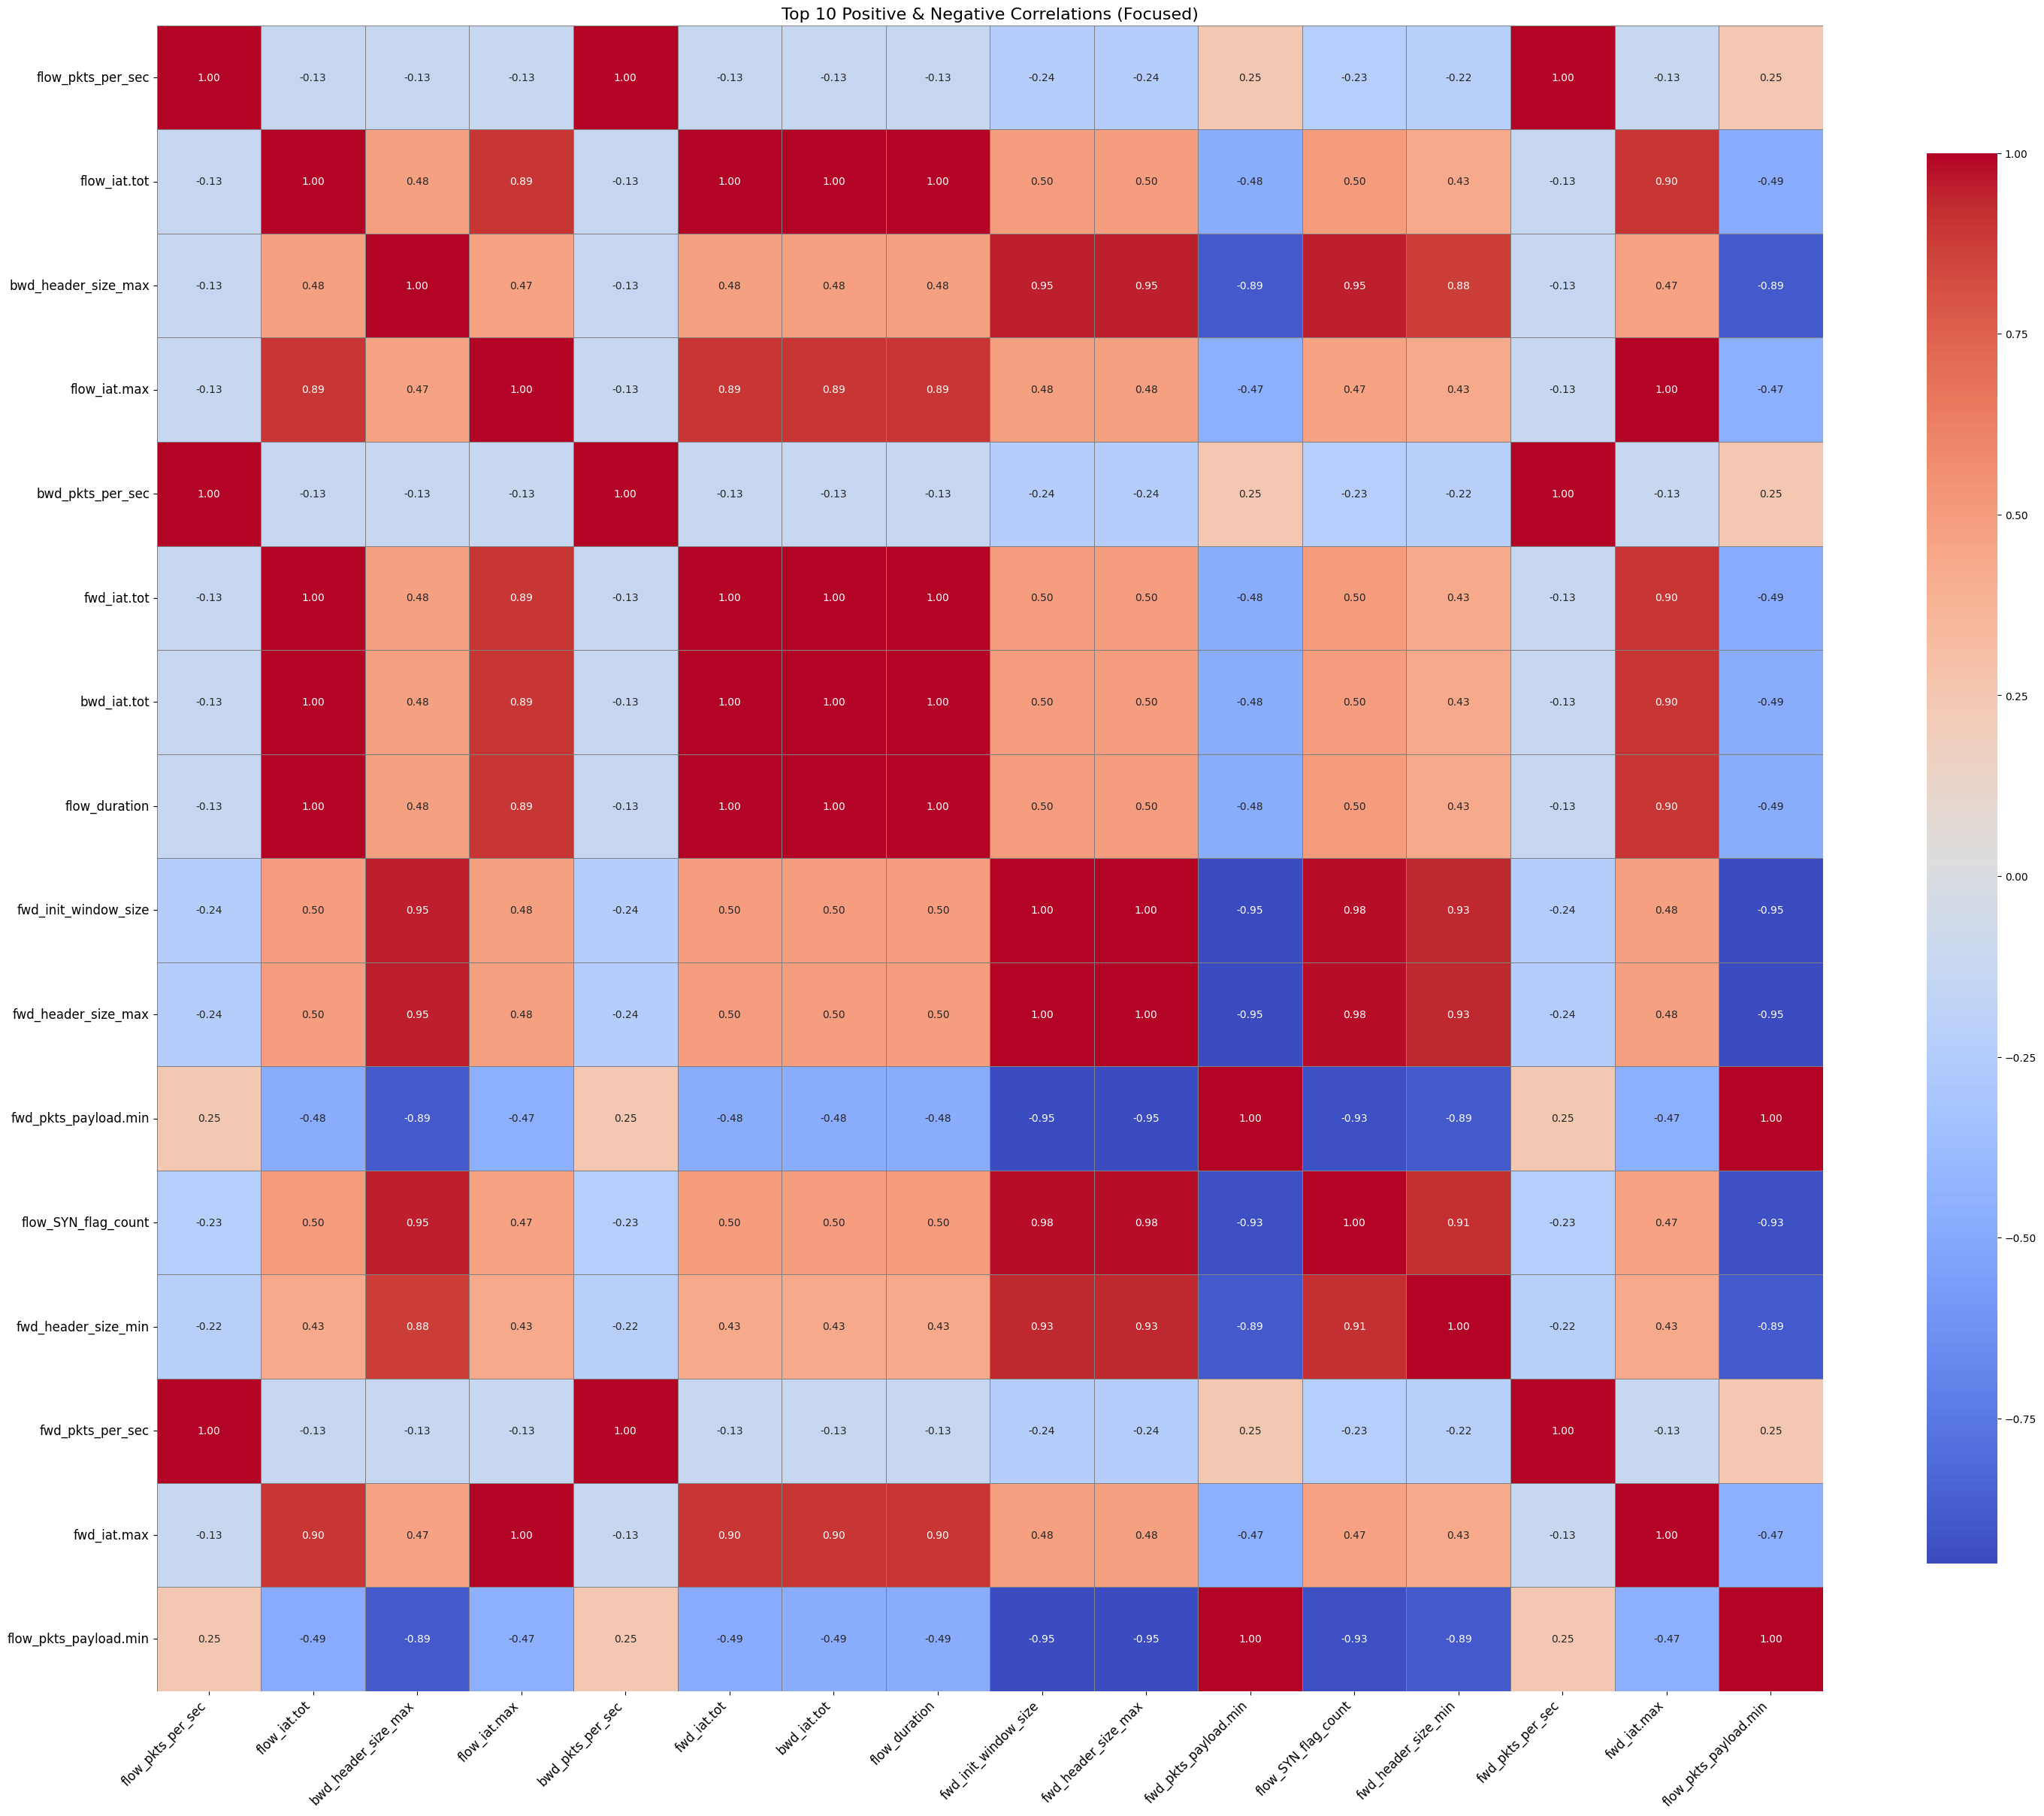

In [38]:
plot_focused_top_correlations(arp, top_n=10)

In [39]:
ddos_loris=pd.read_csv('DDOS_Slowloris.csv')
ddos_loris.head(12)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
521,80,51470,80,tcp,http,0.000515,8,0,2,0,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,65476,0,0,DDOS_Slowloris
1197,405,49682,80,tcp,http,0.005089,4,3,2,0,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64240,65160,502,DDOS_Slowloris
1265,234,55280,80,tcp,http,30.561390,8,7,4,1,...,1.927730e+06,1.148042e+07,1.573777e+07,2.721819e+07,1.360909e+07,3.010407e+06,64240,65160,501,DDOS_Slowloris
1279,324,55460,80,tcp,http,24.207702,6,5,4,0,...,1.337624e+03,5.136984e+06,1.906839e+07,2.420538e+07,1.210269e+07,9.850993e+06,64240,65160,502,DDOS_Slowloris
1674,352,49574,80,tcp,http,21.218123,5,4,3,0,...,2.858062e+03,2.121407e+07,2.121407e+07,2.121407e+07,2.121407e+07,0.000000e+00,64240,65160,502,DDOS_Slowloris
1756,354,49578,80,tcp,http,21.213869,5,4,3,0,...,2.338982e+03,2.121055e+07,2.121055e+07,2.121055e+07,2.121055e+07,0.000000e+00,64240,65160,502,DDOS_Slowloris
1818,361,49592,80,tcp,http,21.190135,5,4,3,0,...,4.578328e+03,2.118365e+07,2.118365e+07,2.118365e+07,2.118365e+07,0.000000e+00,64240,65160,502,DDOS_Slowloris
2137,127,55066,80,tcp,http,30.802314,7,13,4,6,...,6.001299e+06,8.683127e+06,1.172020e+07,2.040333e+07,1.020166e+07,2.147535e+06,64240,65160,501,DDOS_Slowloris
2142,52,51416,80,tcp,http,0.000529,8,0,2,0,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,65476,0,0,DDOS_Slowloris
2229,302,55416,80,tcp,http,25.294968,6,5,4,0,...,1.685606e+03,6.225413e+06,1.906661e+07,2.529203e+07,1.264601e+07,9.080100e+06,64240,65160,502,DDOS_Slowloris


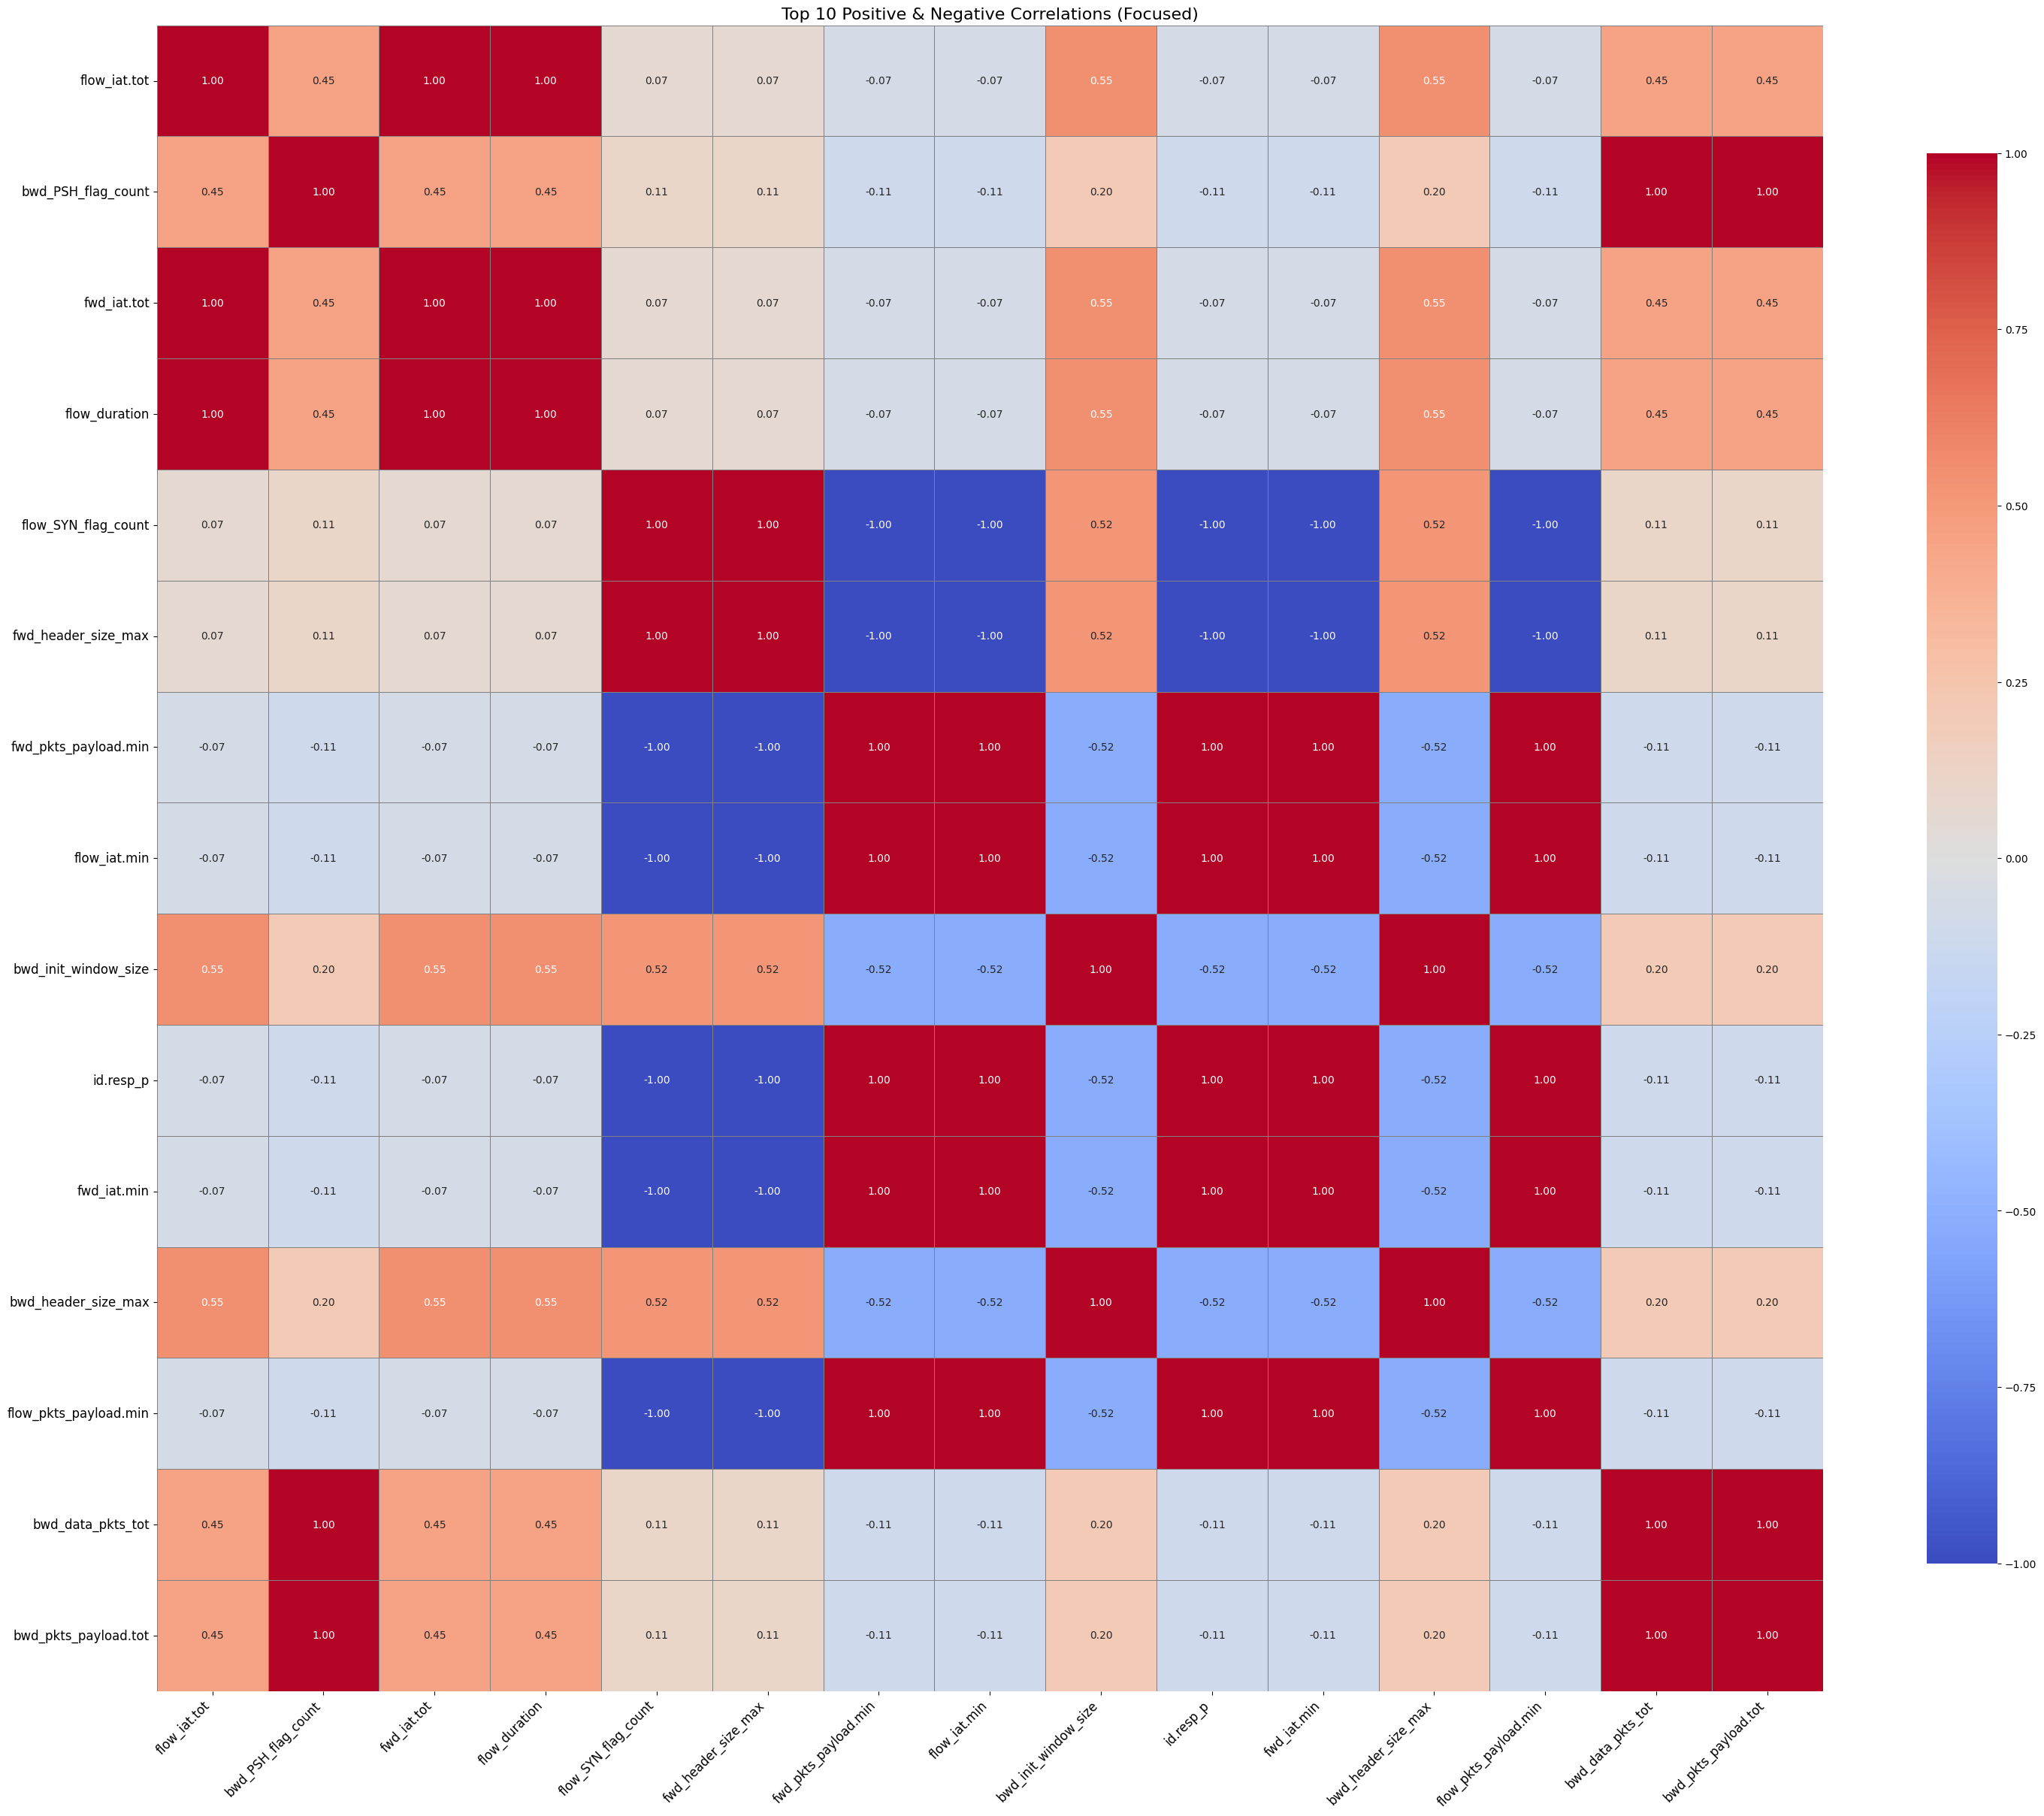

In [40]:
plot_focused_top_correlations(ddos_loris, top_n=10)

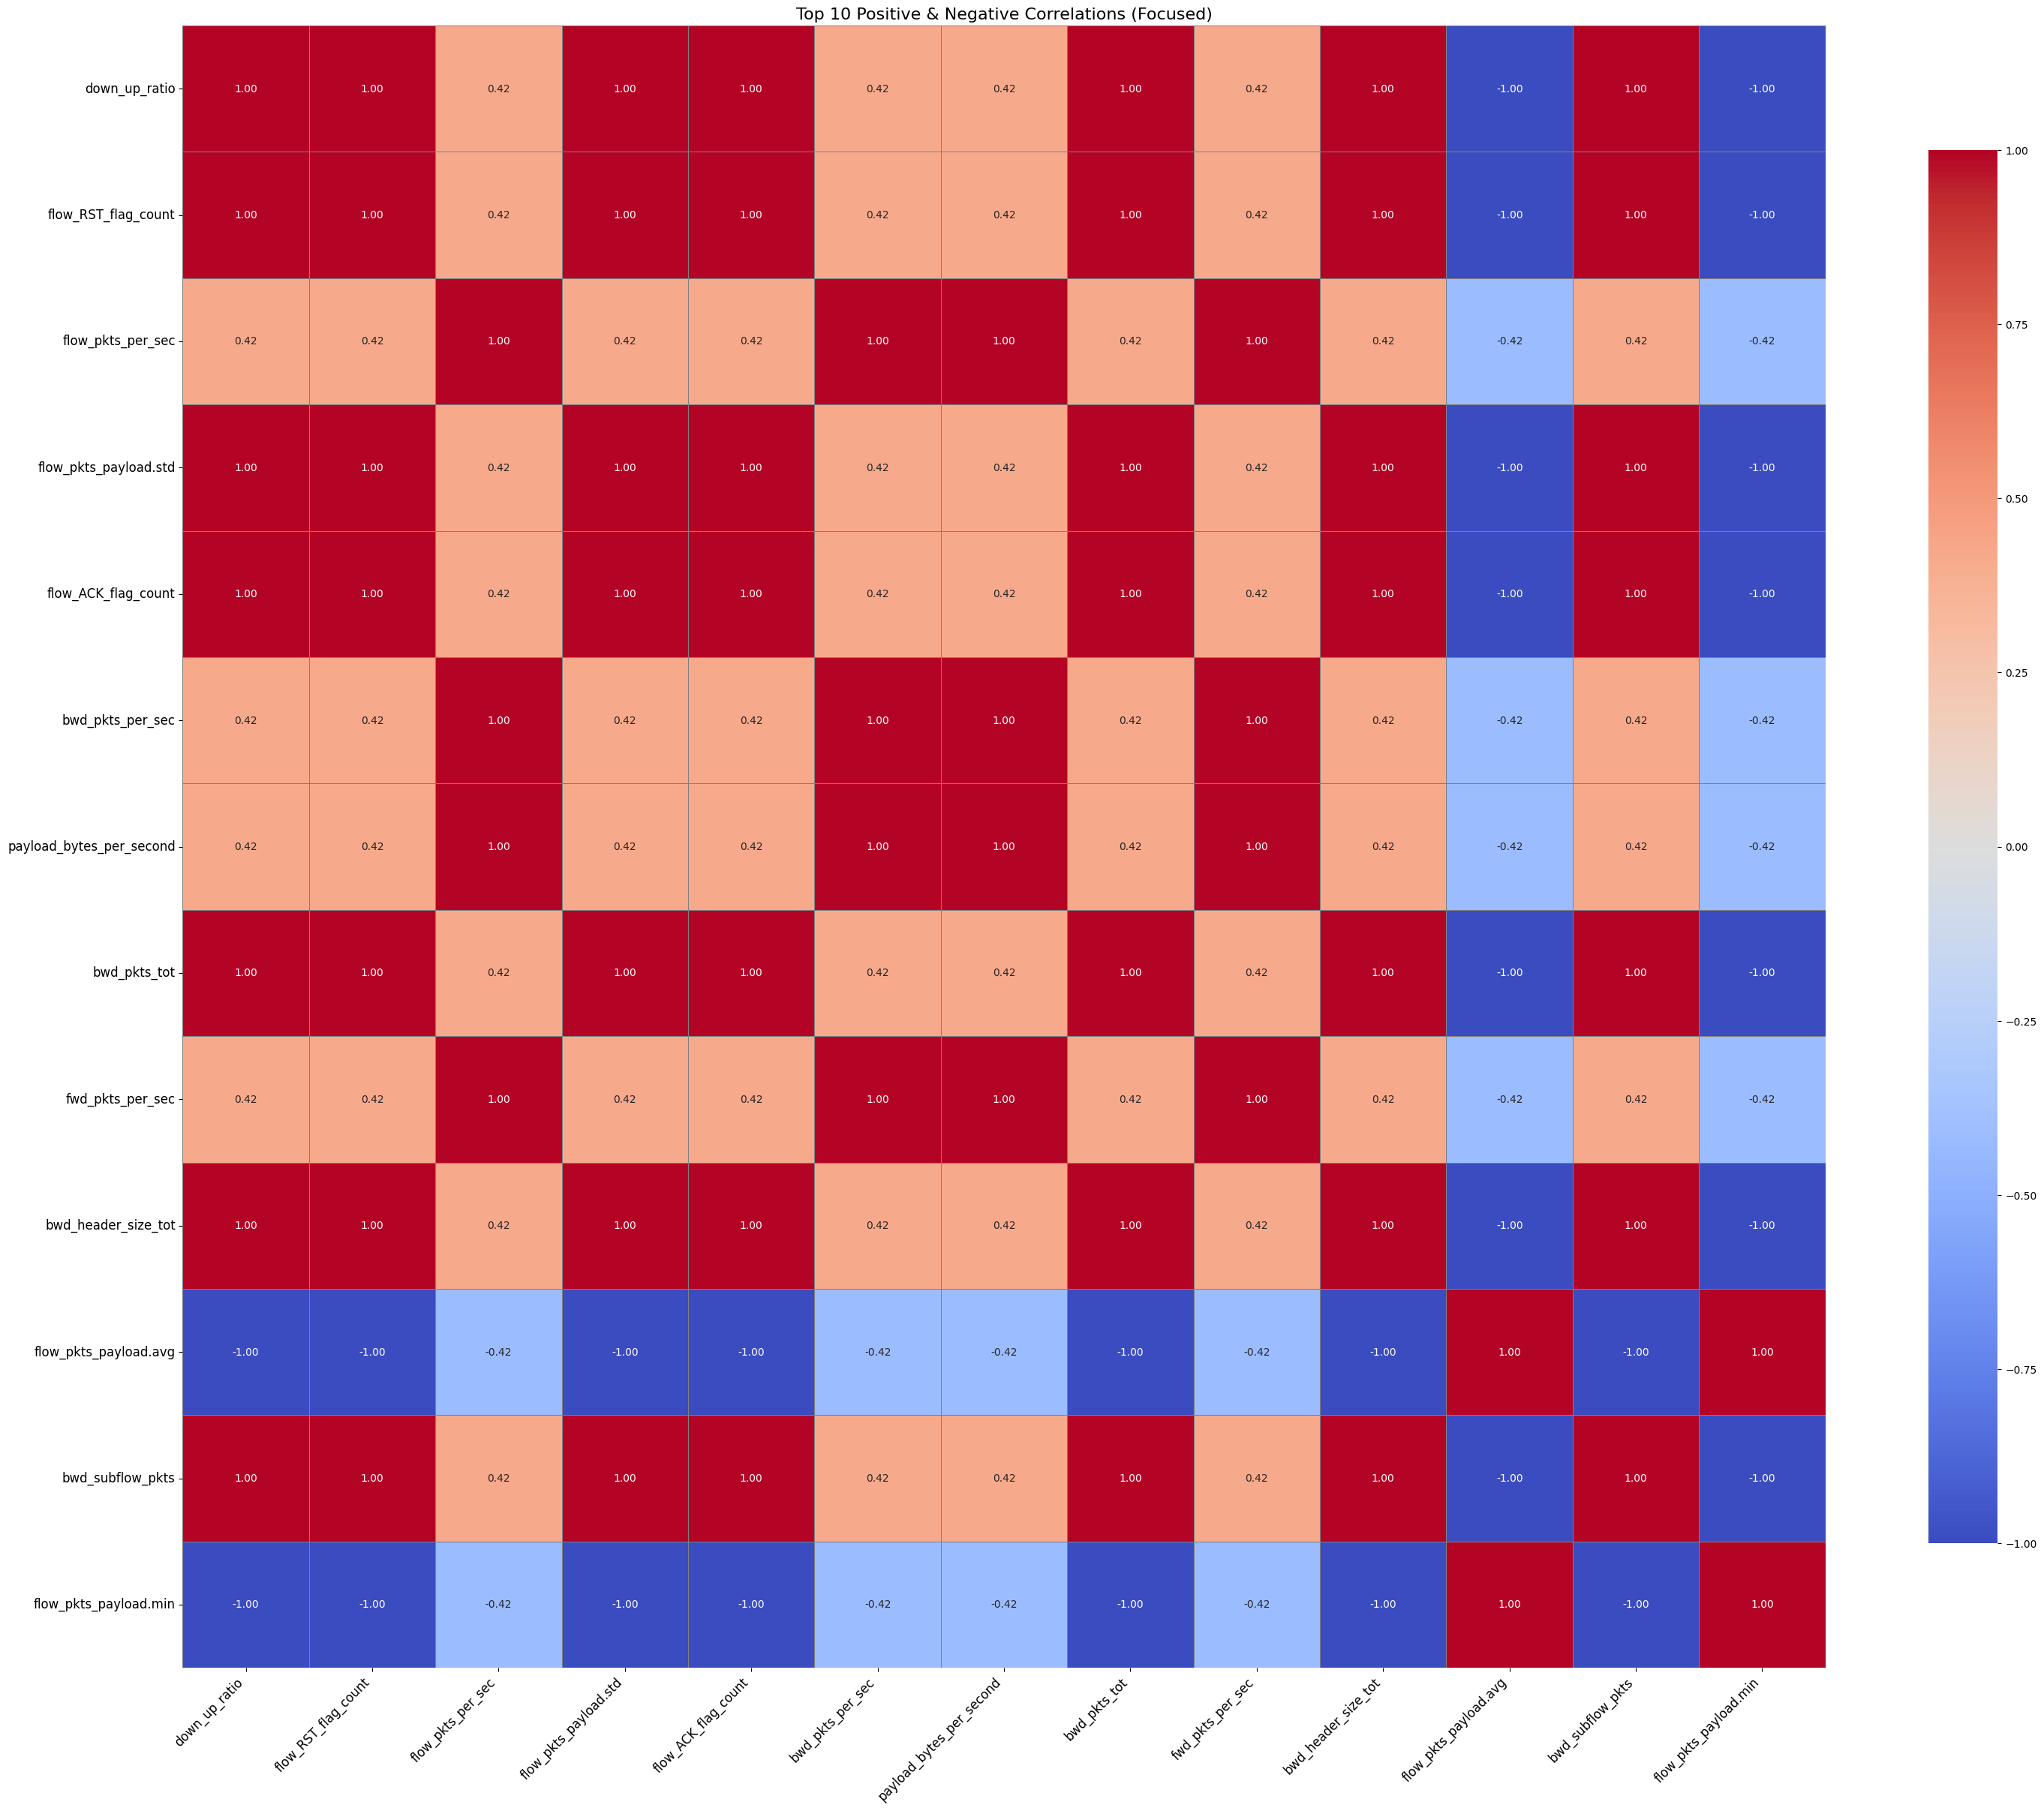

In [41]:
dos_syn=pd.read_csv('DOS_SYN_Hping.csv')
plot_focused_top_correlations(dos_syn, top_n=10)

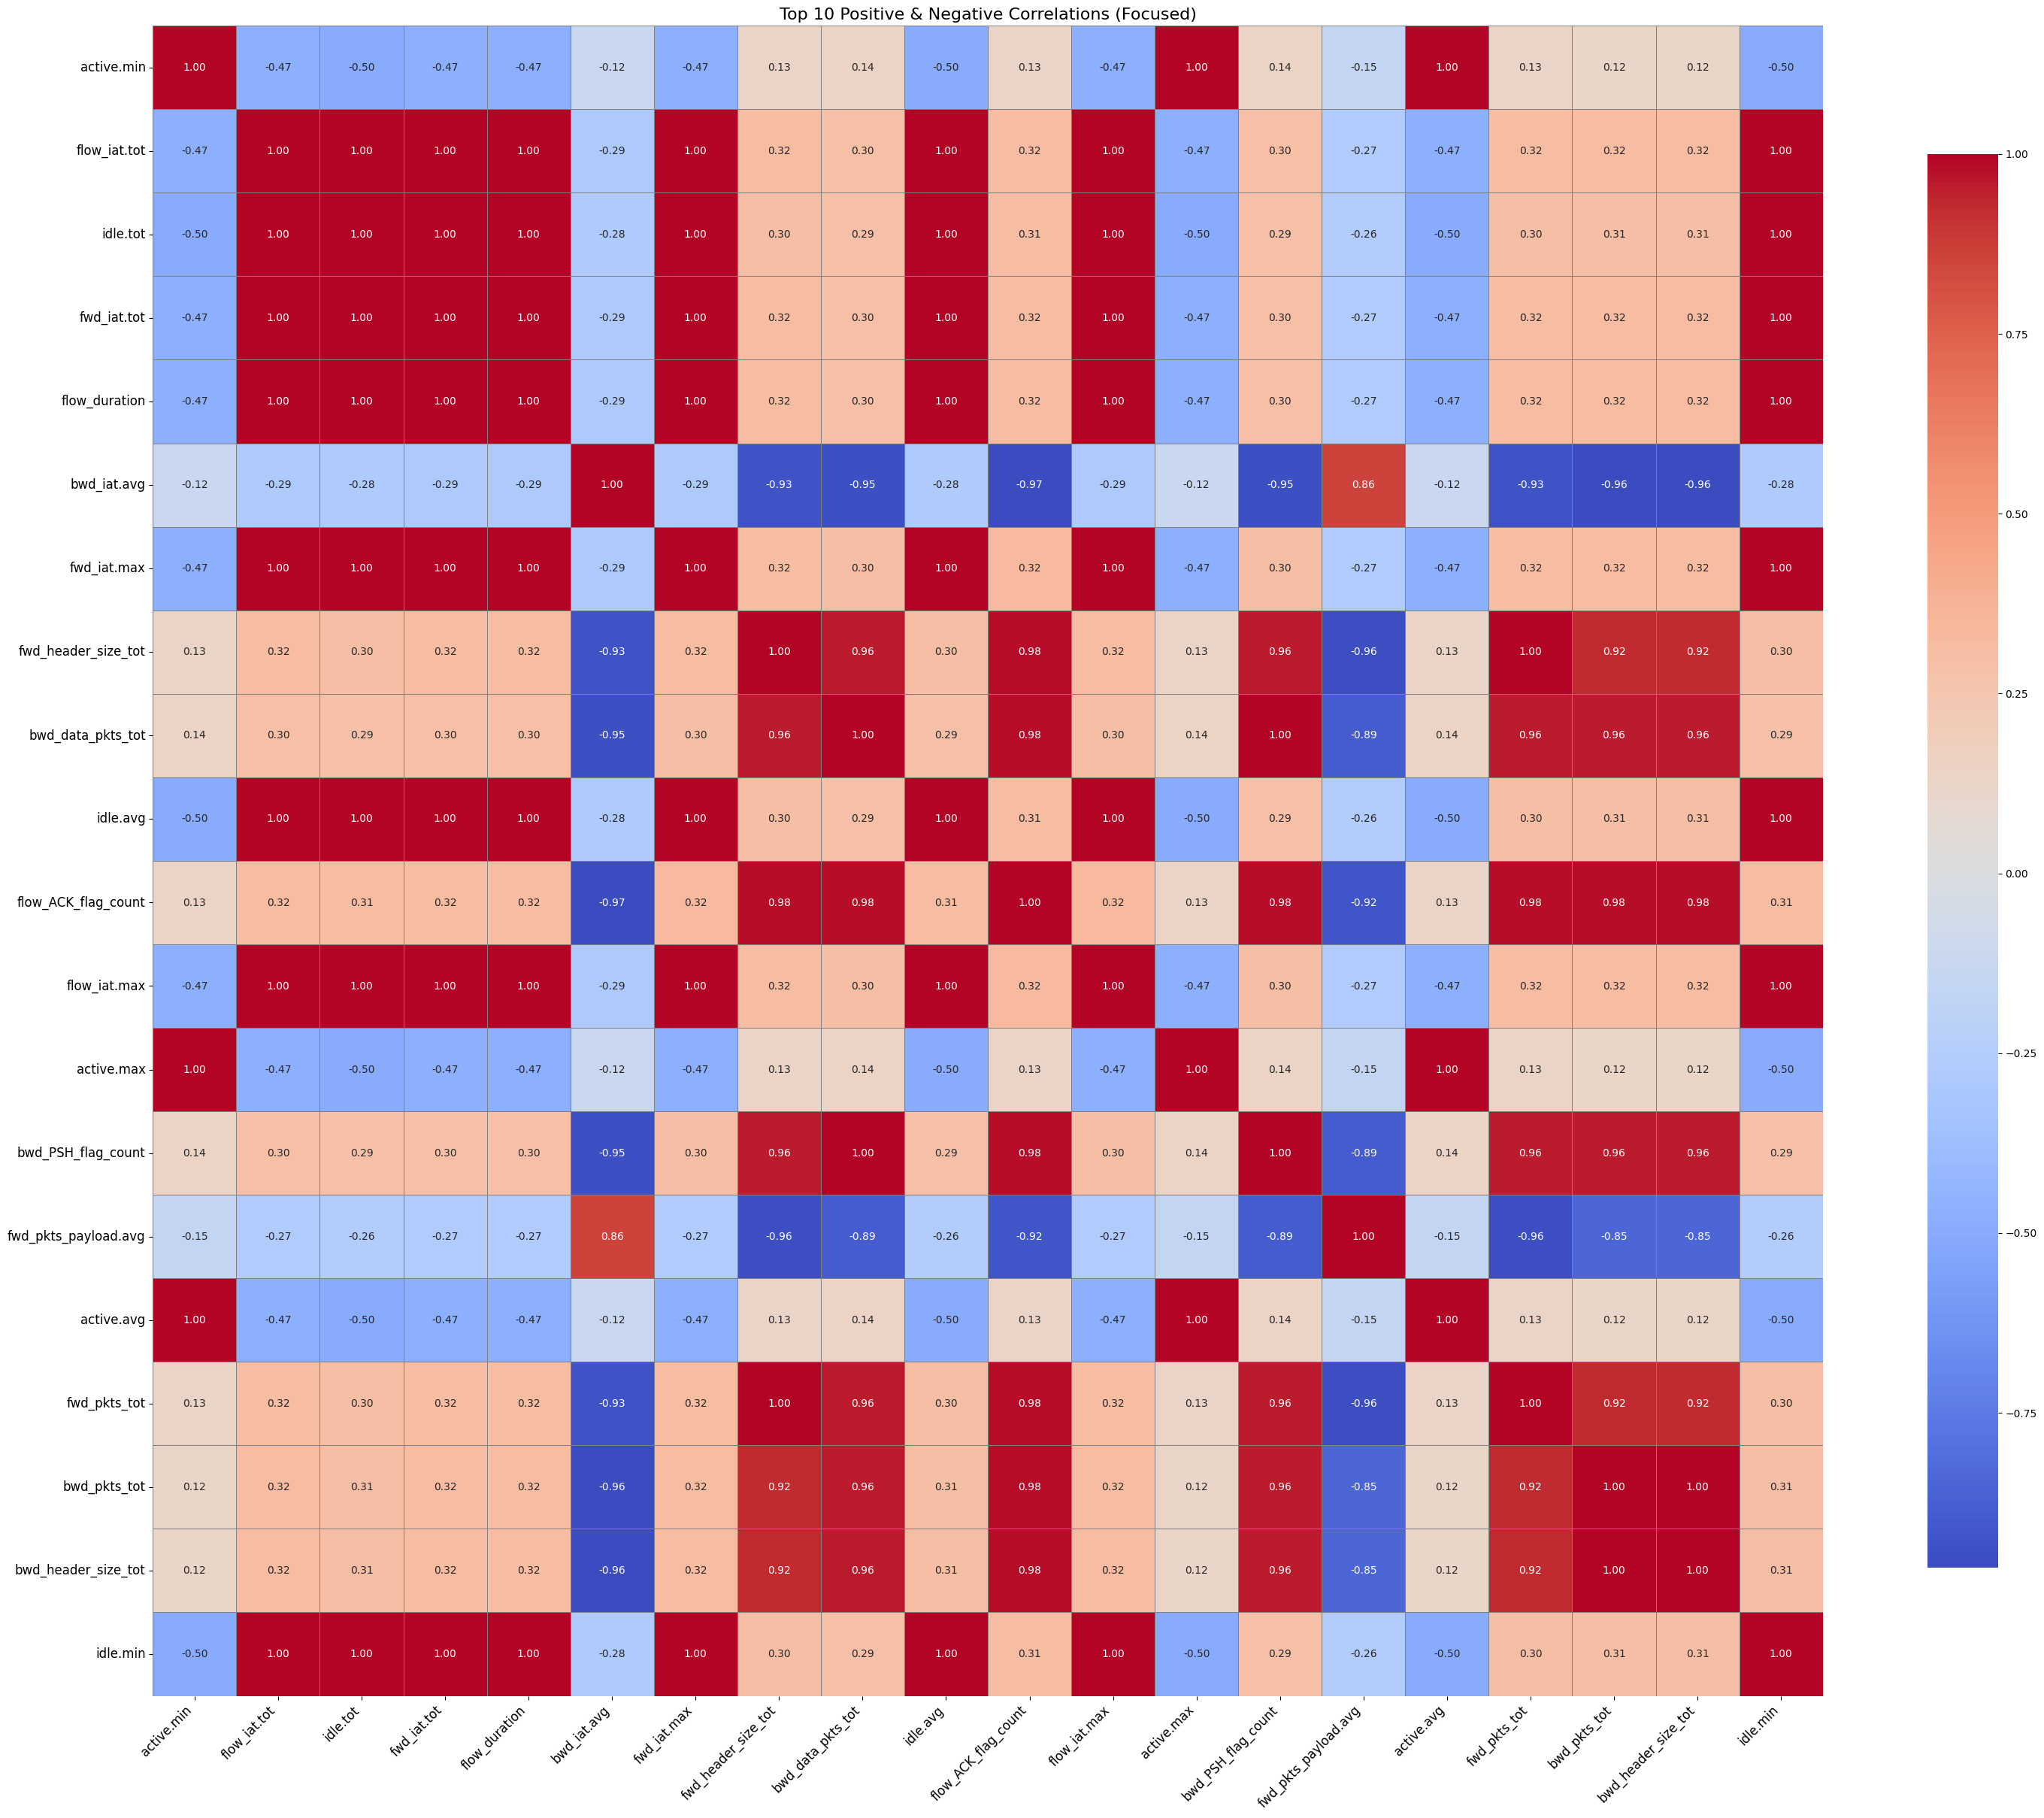

In [42]:
mqtt=pd.read_csv('MQTT_Publish.csv')
plot_focused_top_correlations(mqtt, top_n=10)

C:\Users\FMI\anaconda3\envs\notebook\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
C:\Users\FMI\anaconda3\envs\notebook\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


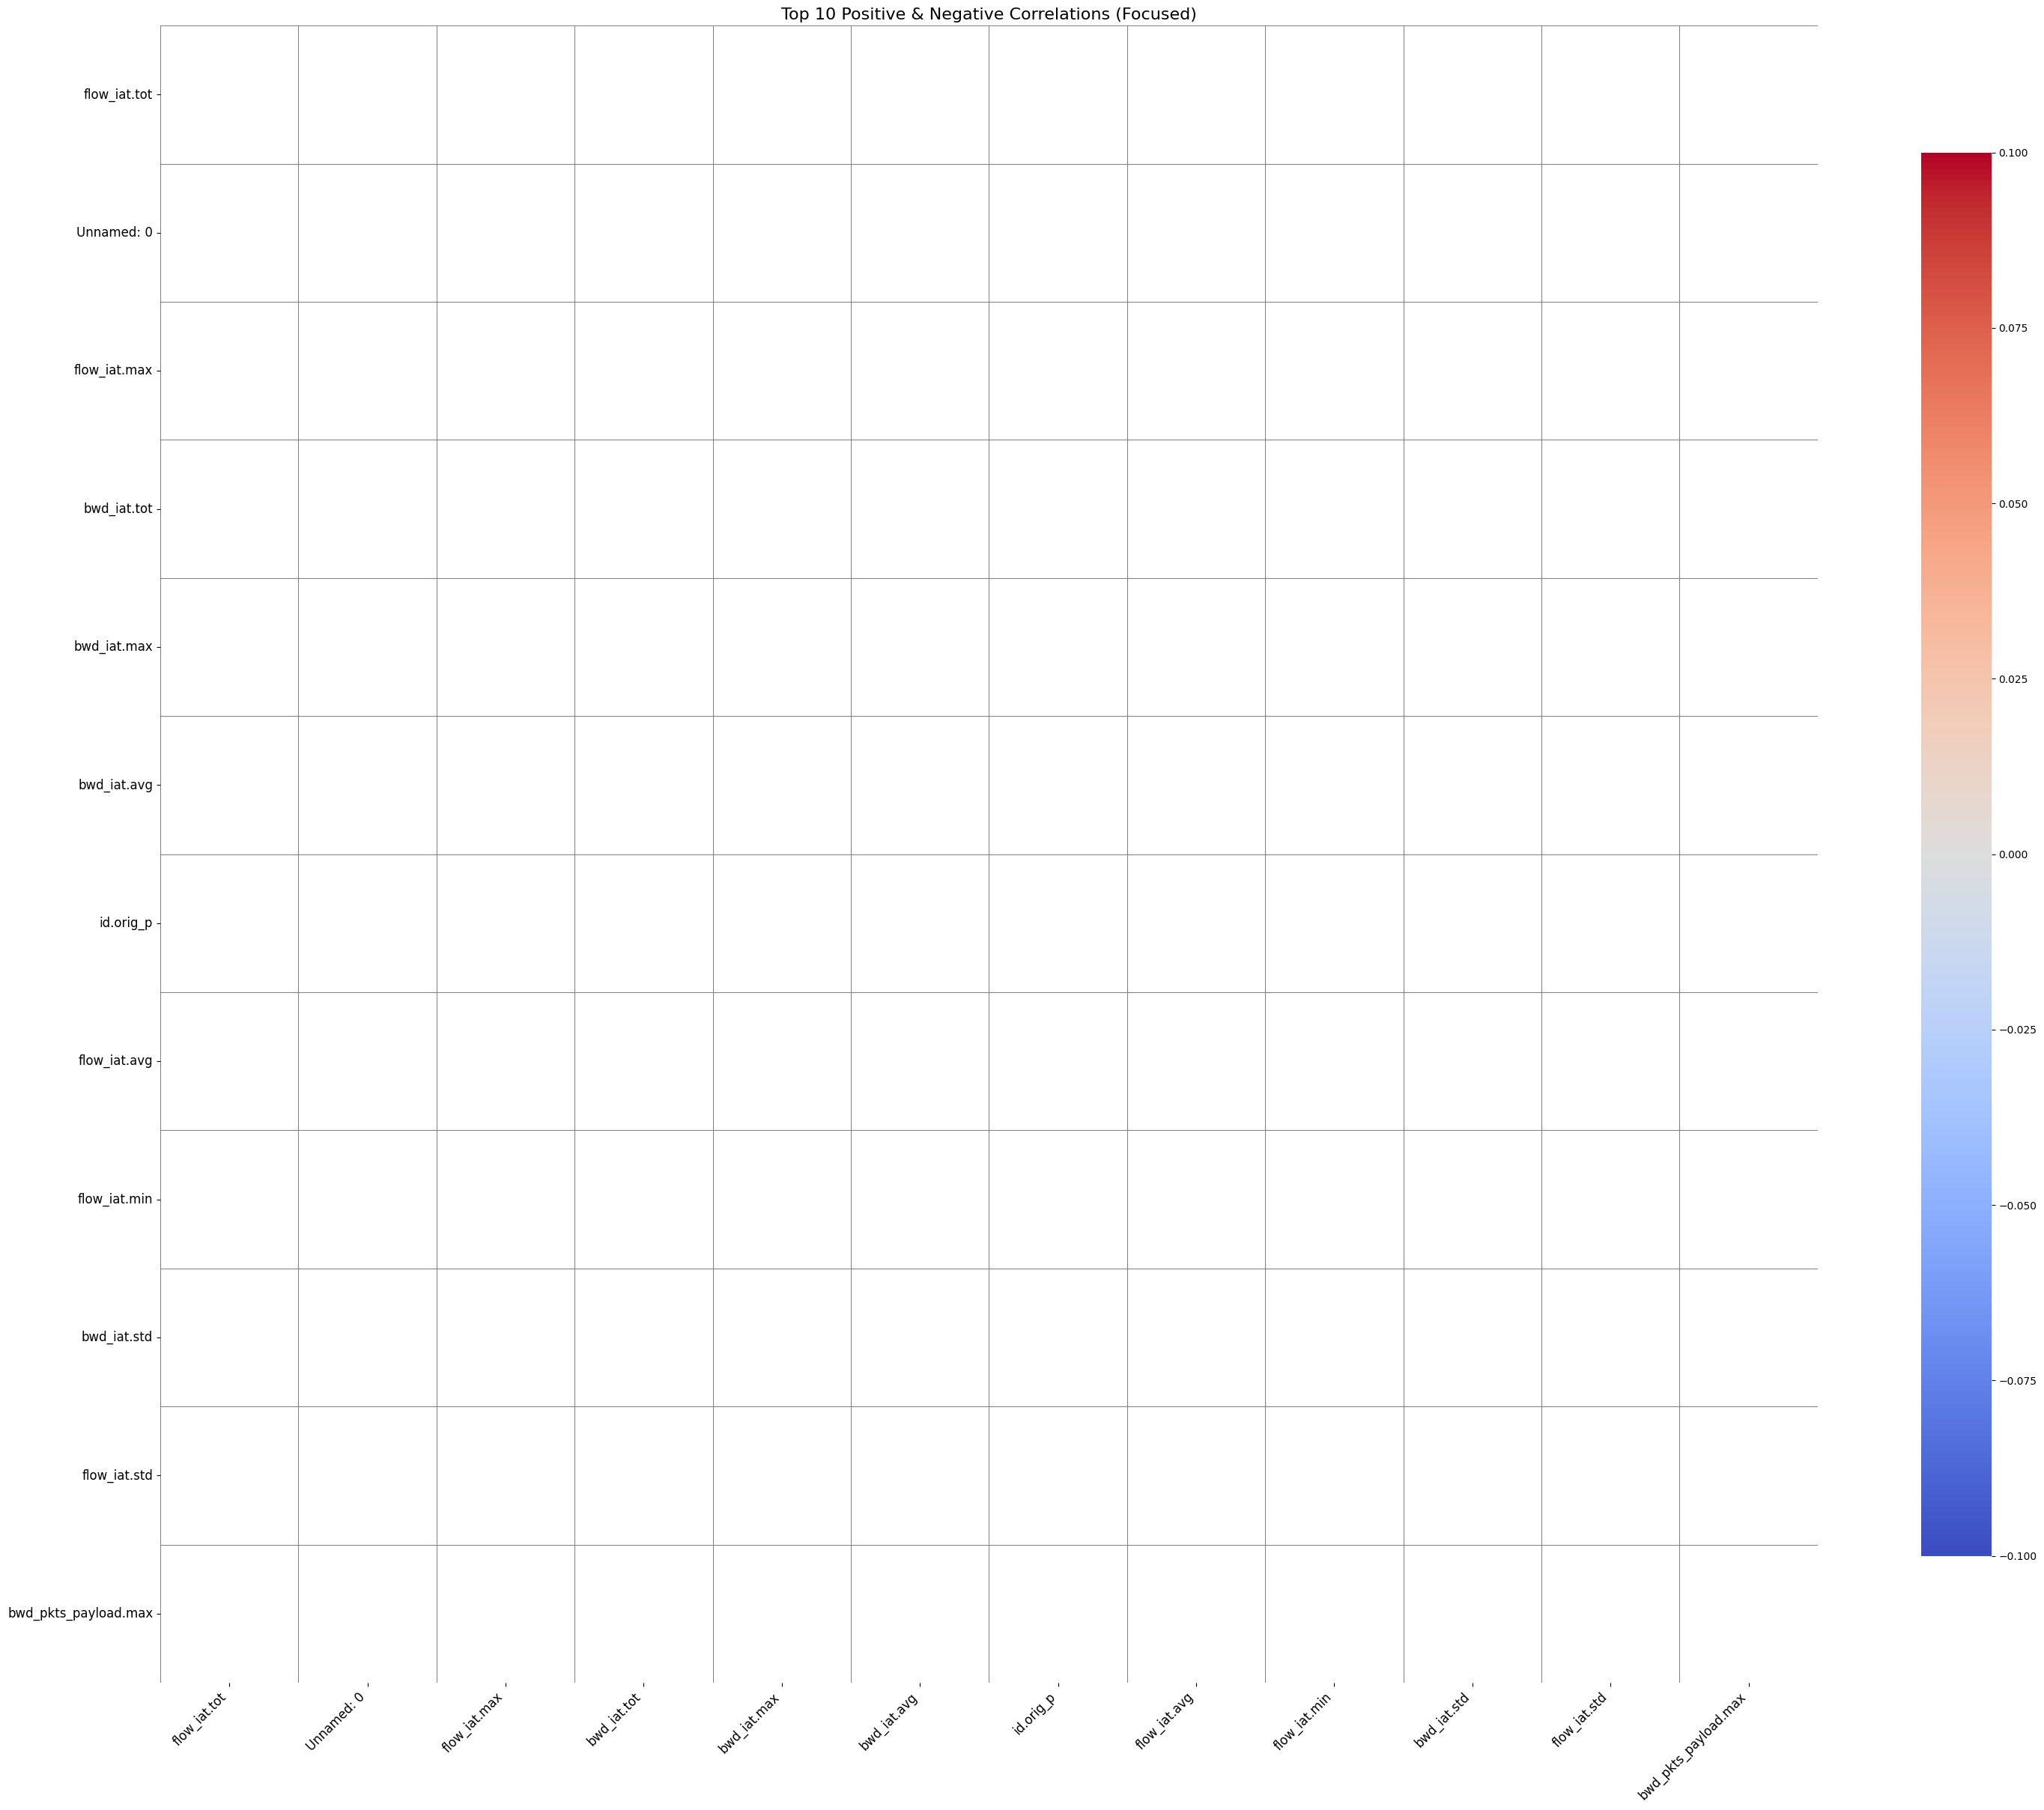

In [44]:
nmap_scan=pd.read_csv('NMAP_FIN_SCAN.csv')
plot_focused_top_correlations(nmap_scan, top_n=10)

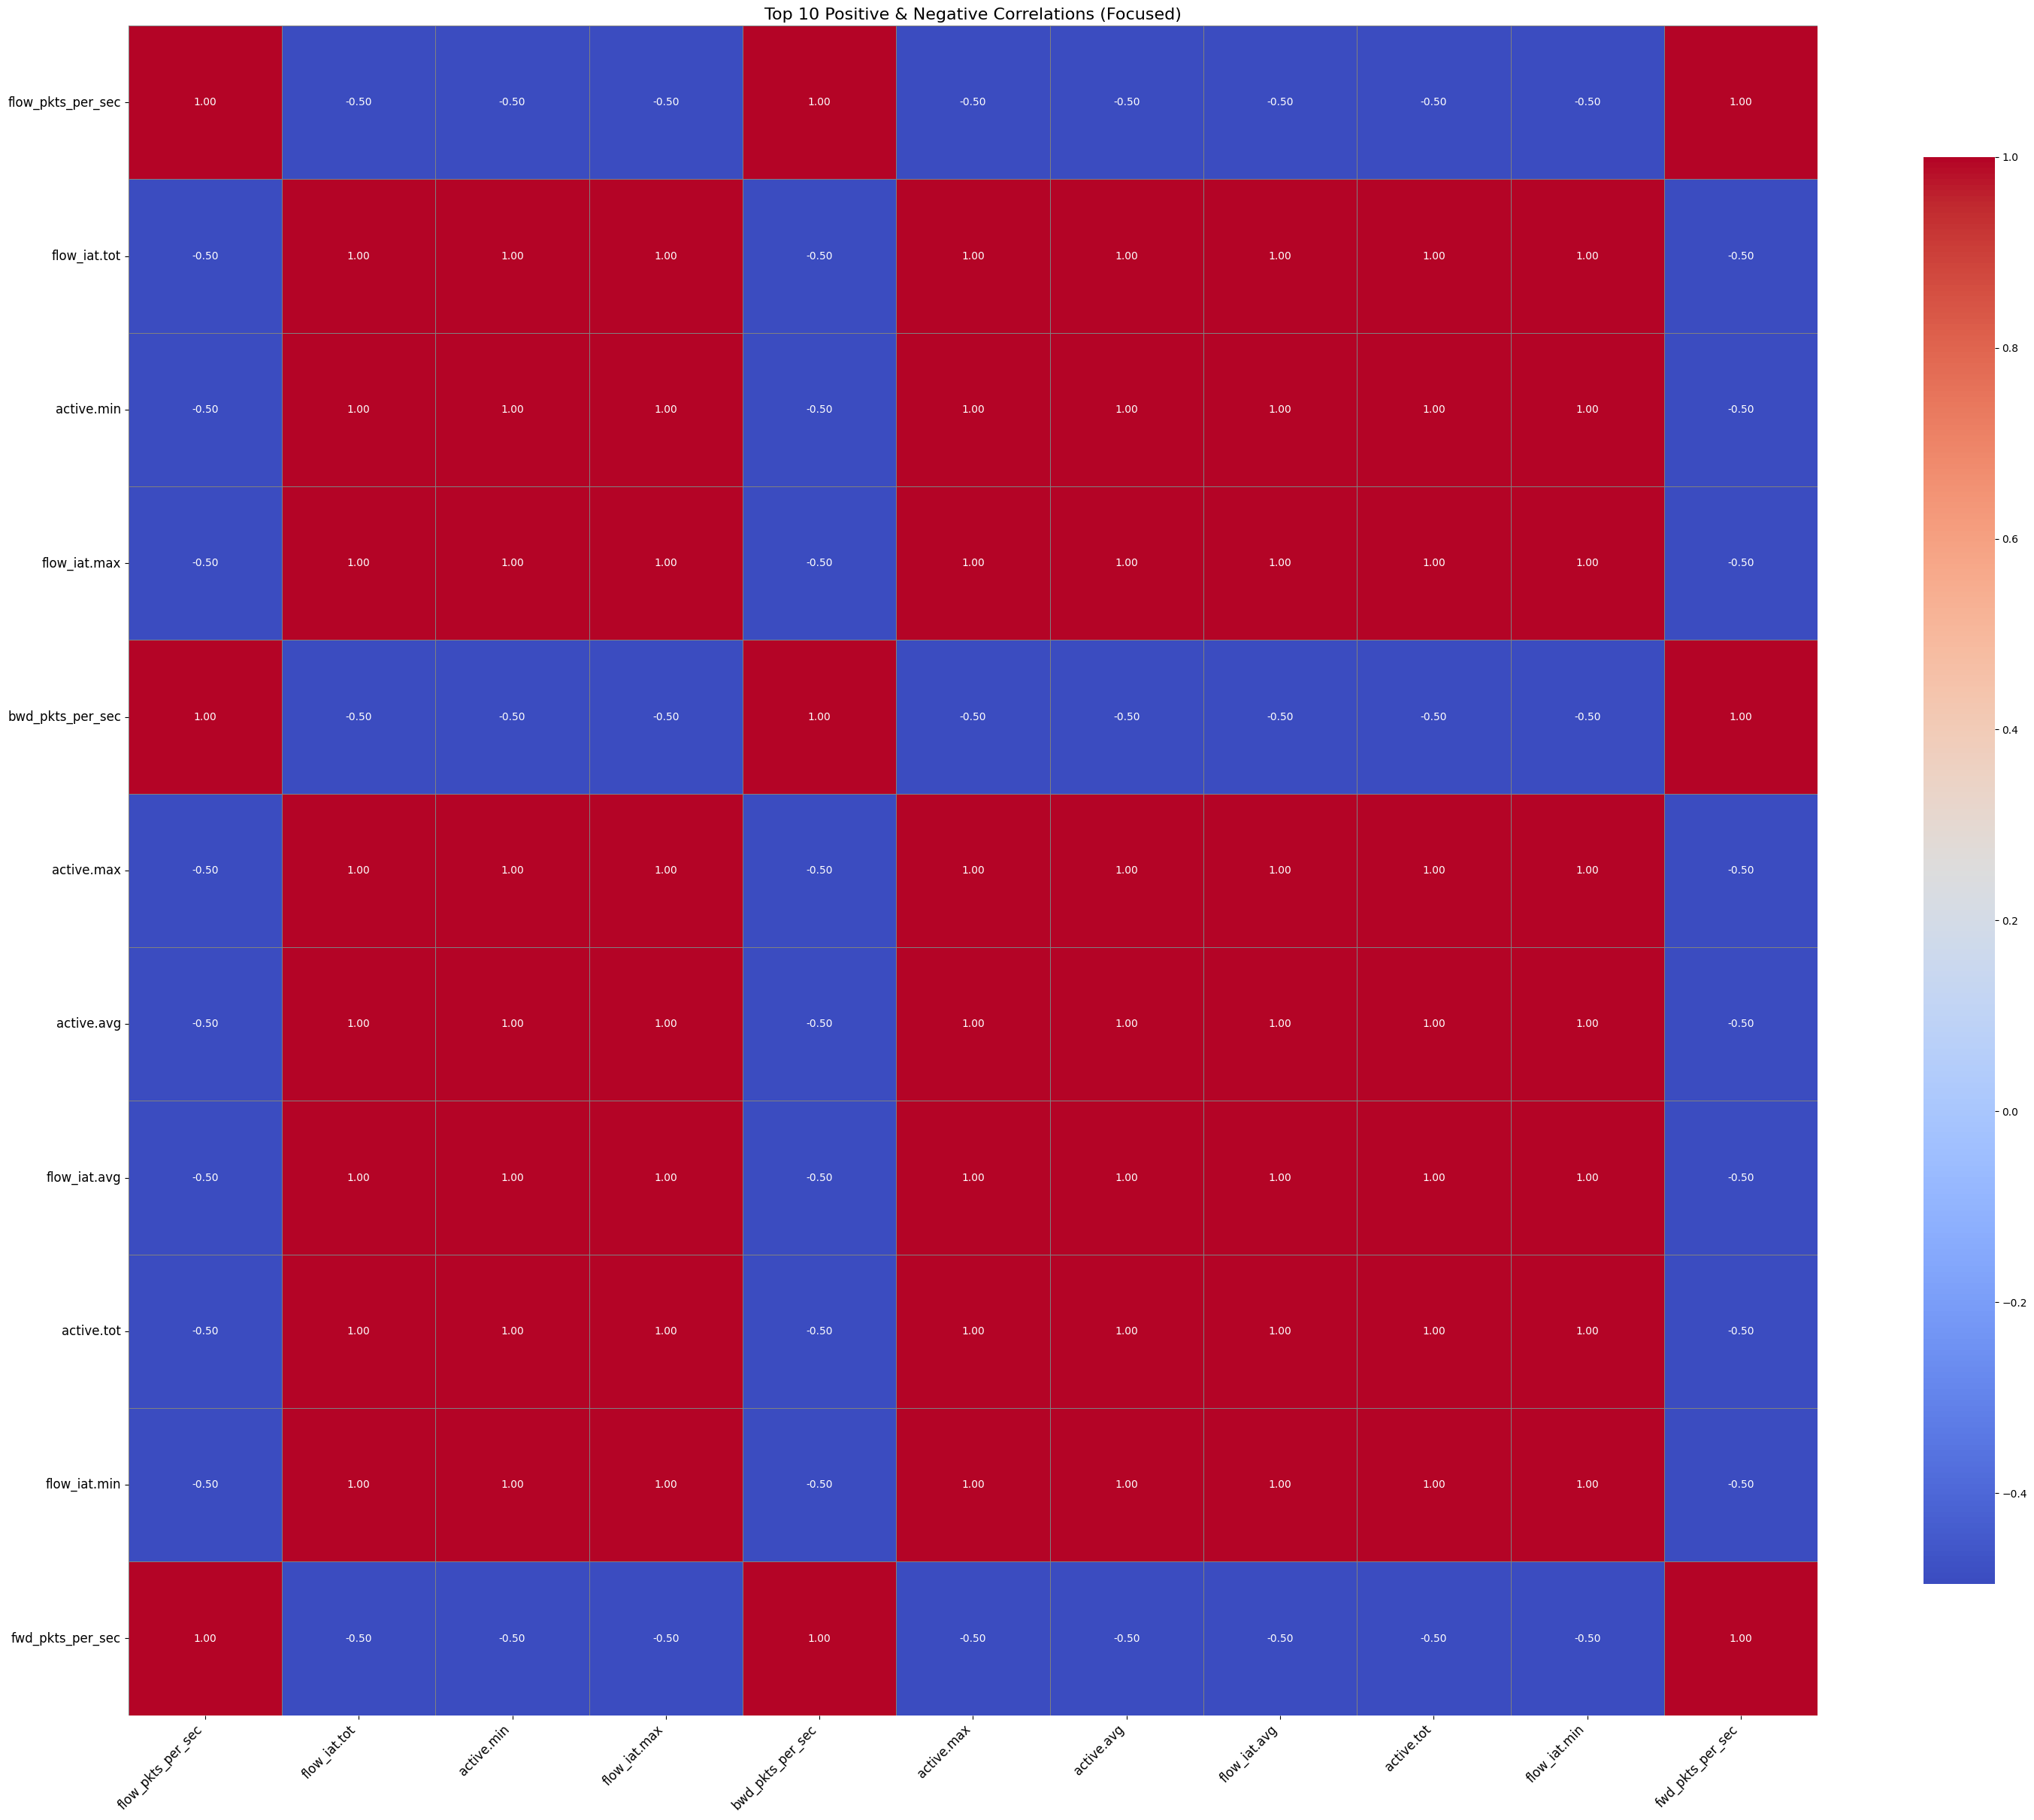

In [45]:
nmap_os=pd.read_csv('NMAP_OS_DETECTION.csv')
plot_focused_top_correlations(nmap_os, top_n=10)

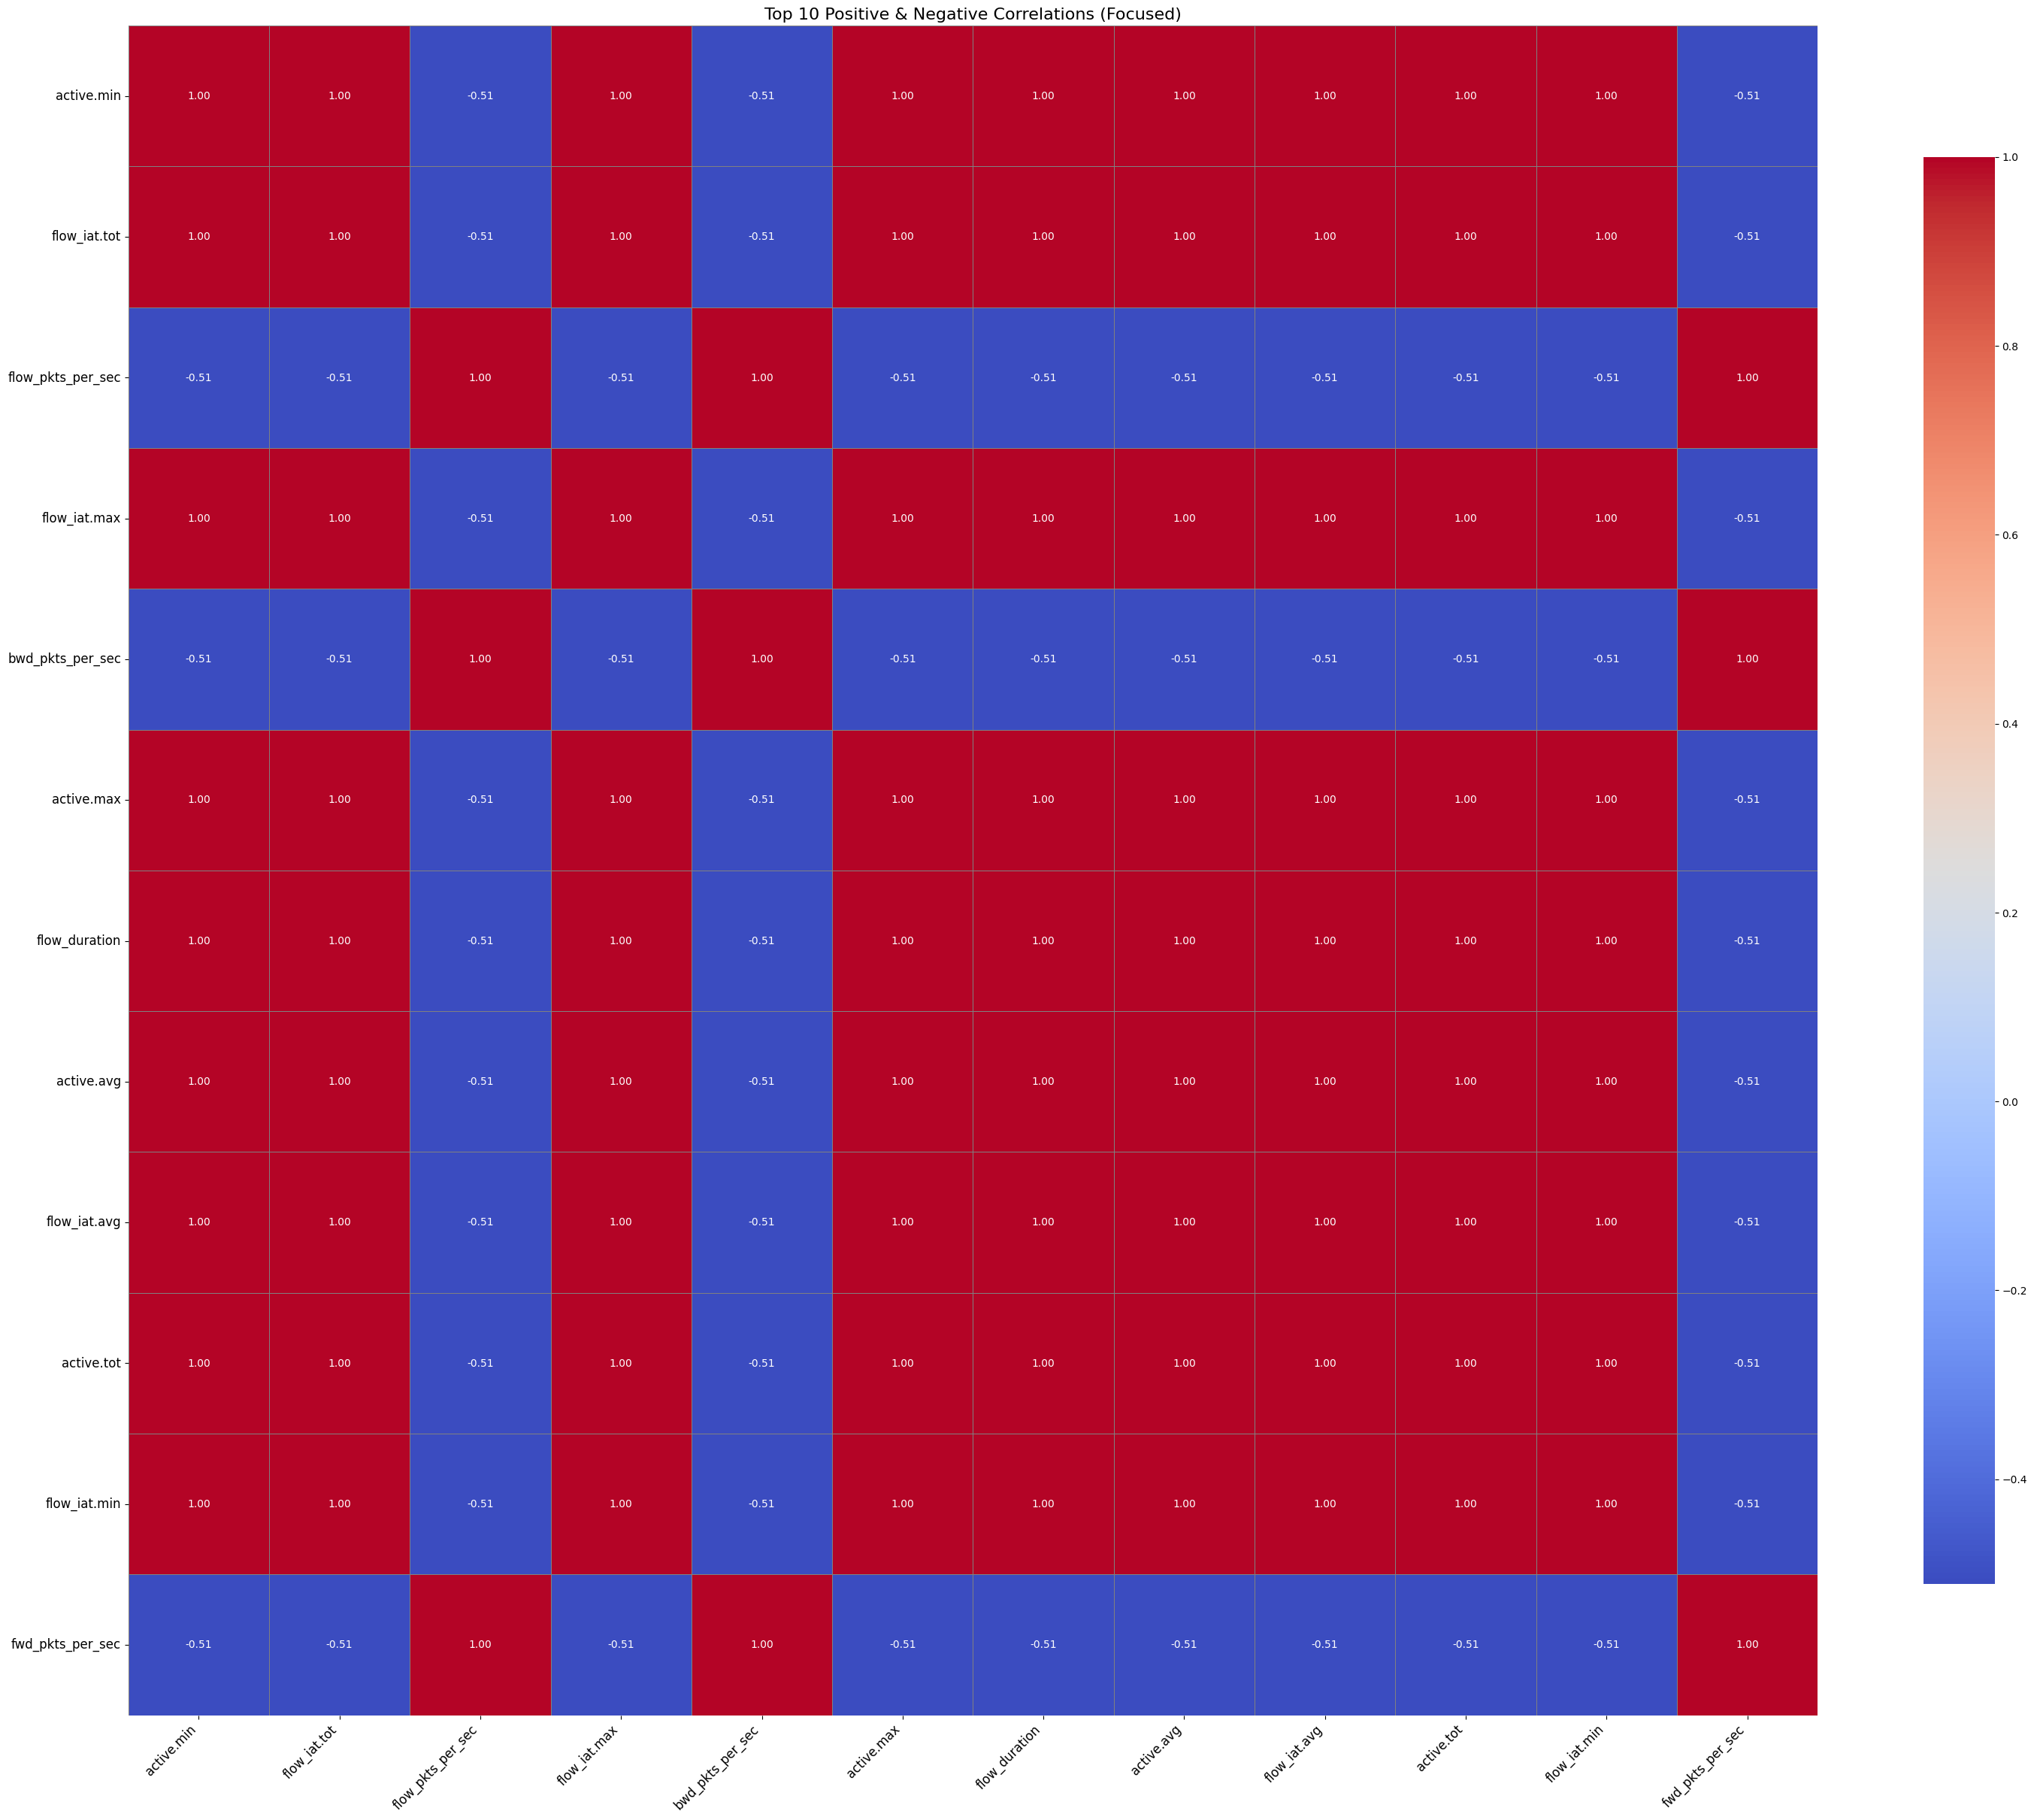

In [46]:
nmap_tcp=pd.read_csv('NMAP_TCP_scan.csv')
plot_focused_top_correlations(nmap_tcp, top_n=10)

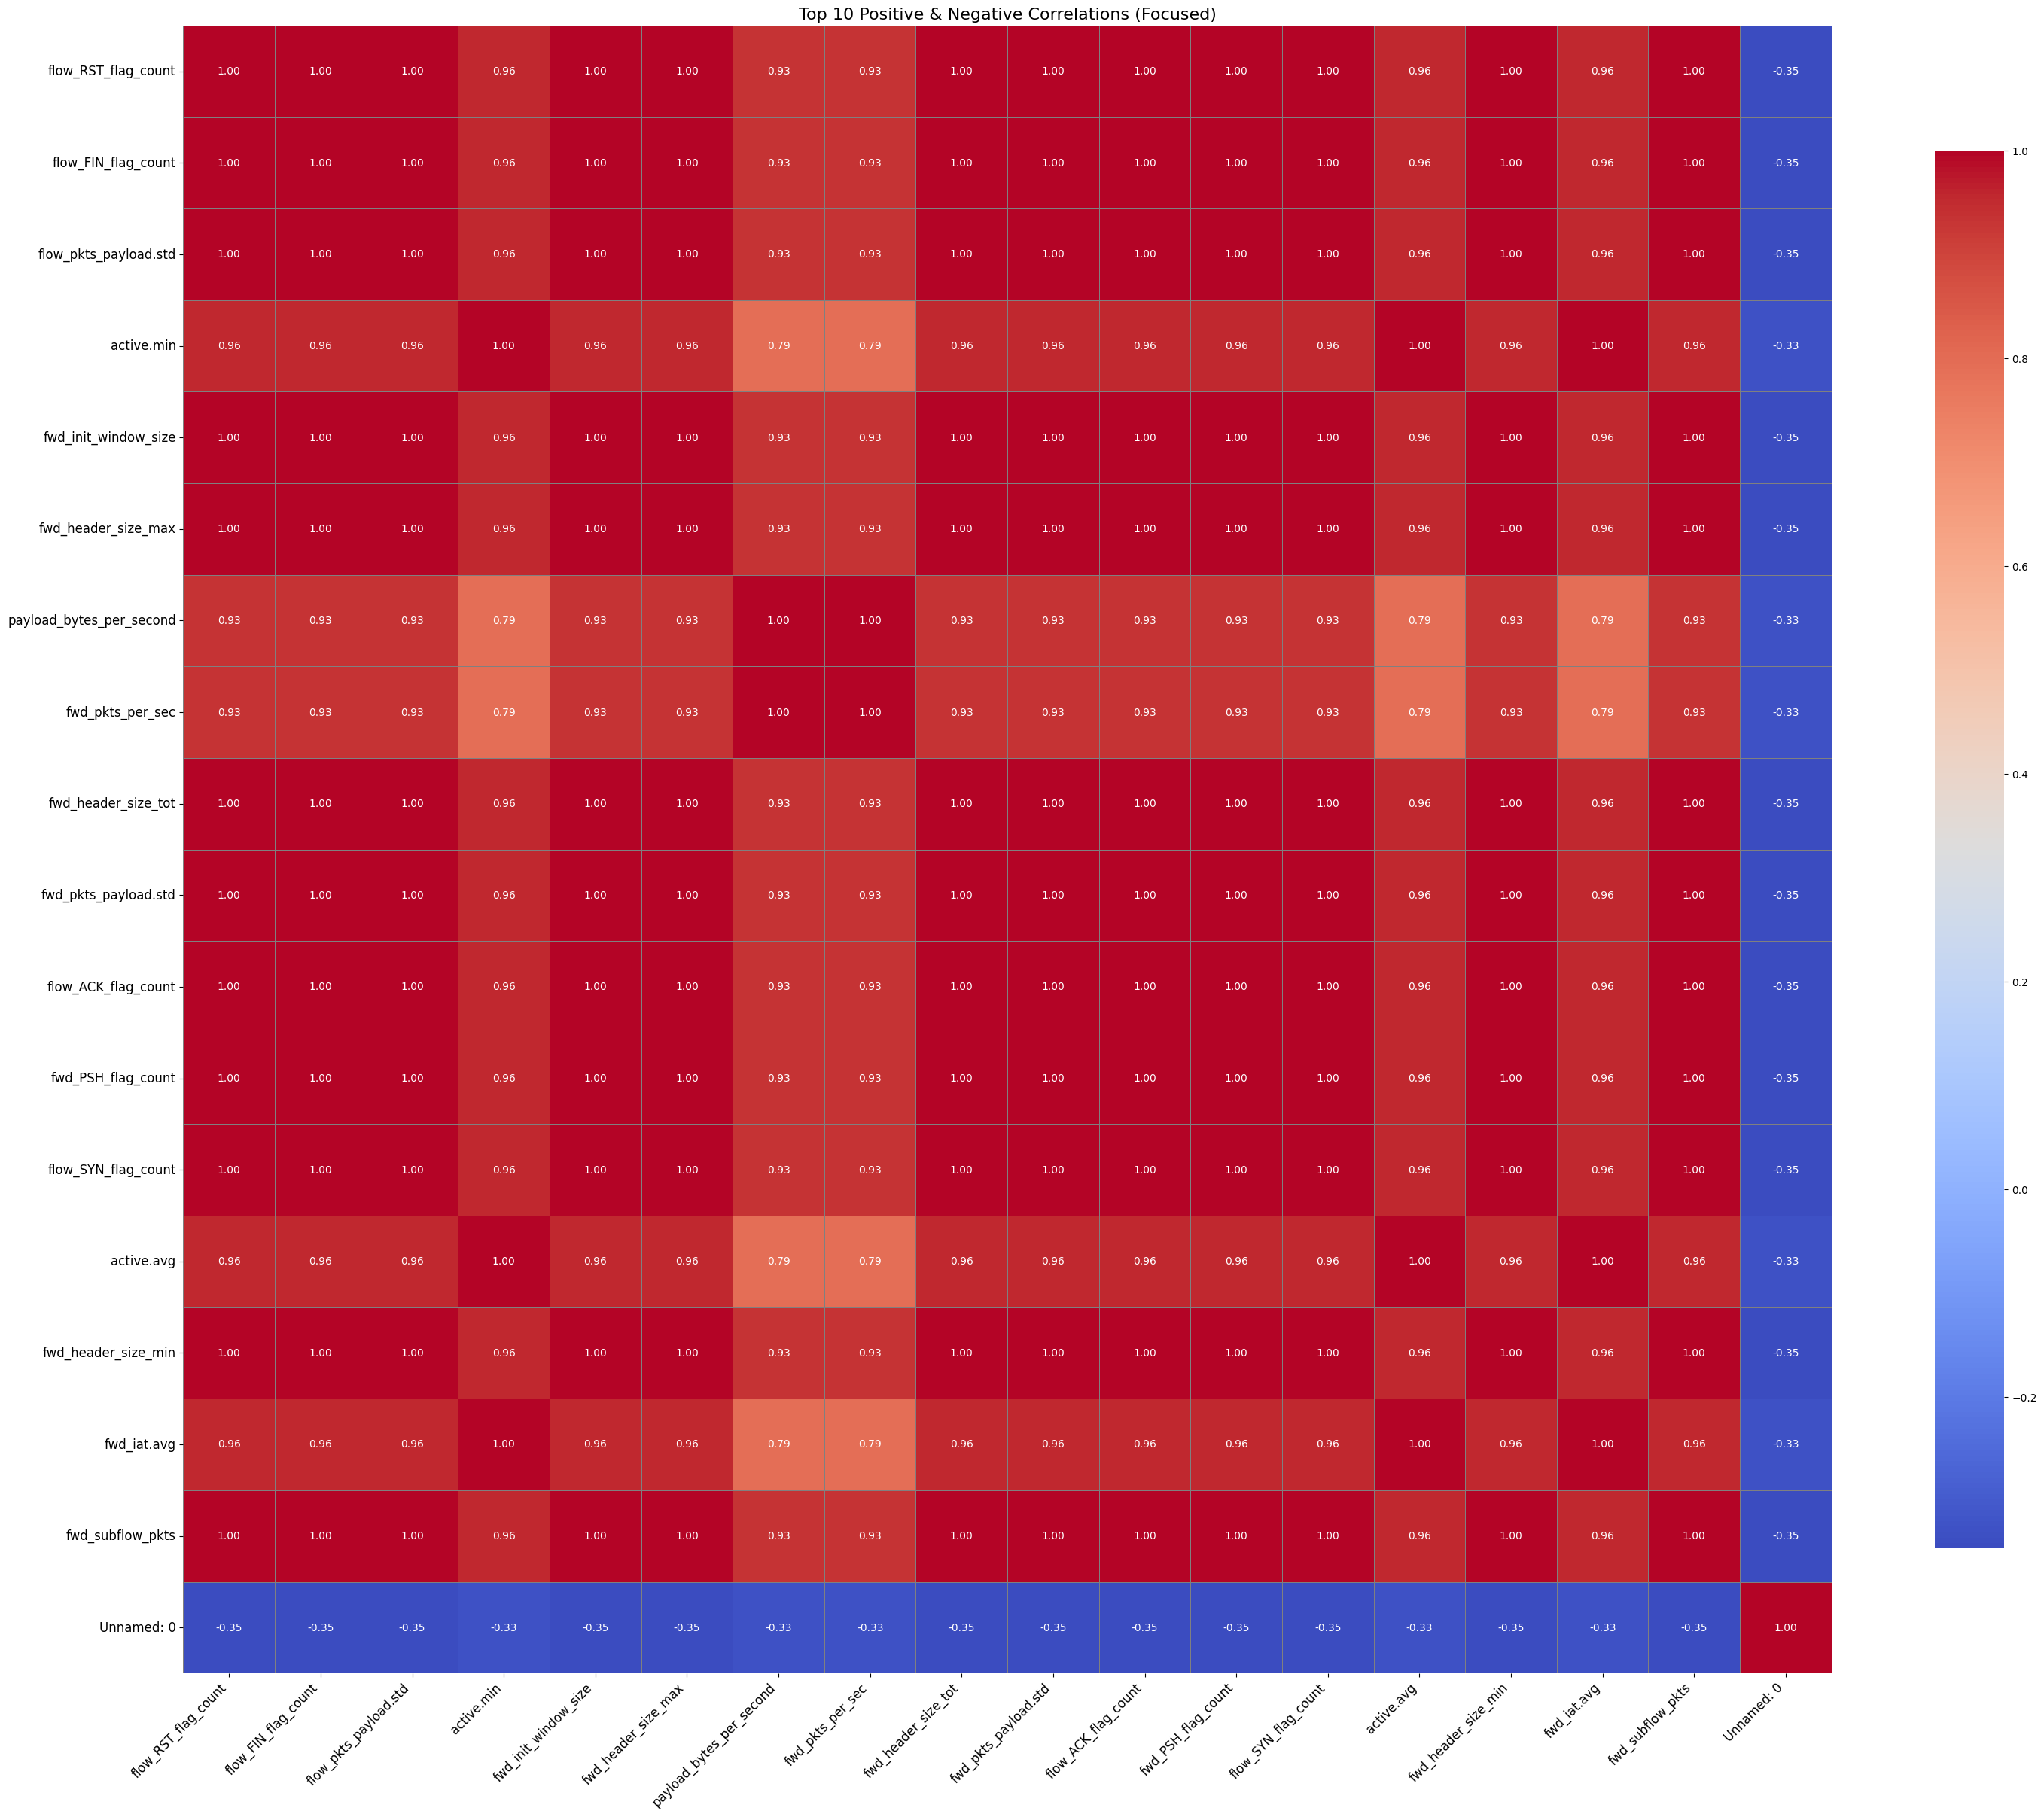

In [47]:
nmap_udp=pd.read_csv('NMAP_UDP_SCAN.csv')
plot_focused_top_correlations(nmap_udp, top_n=10)

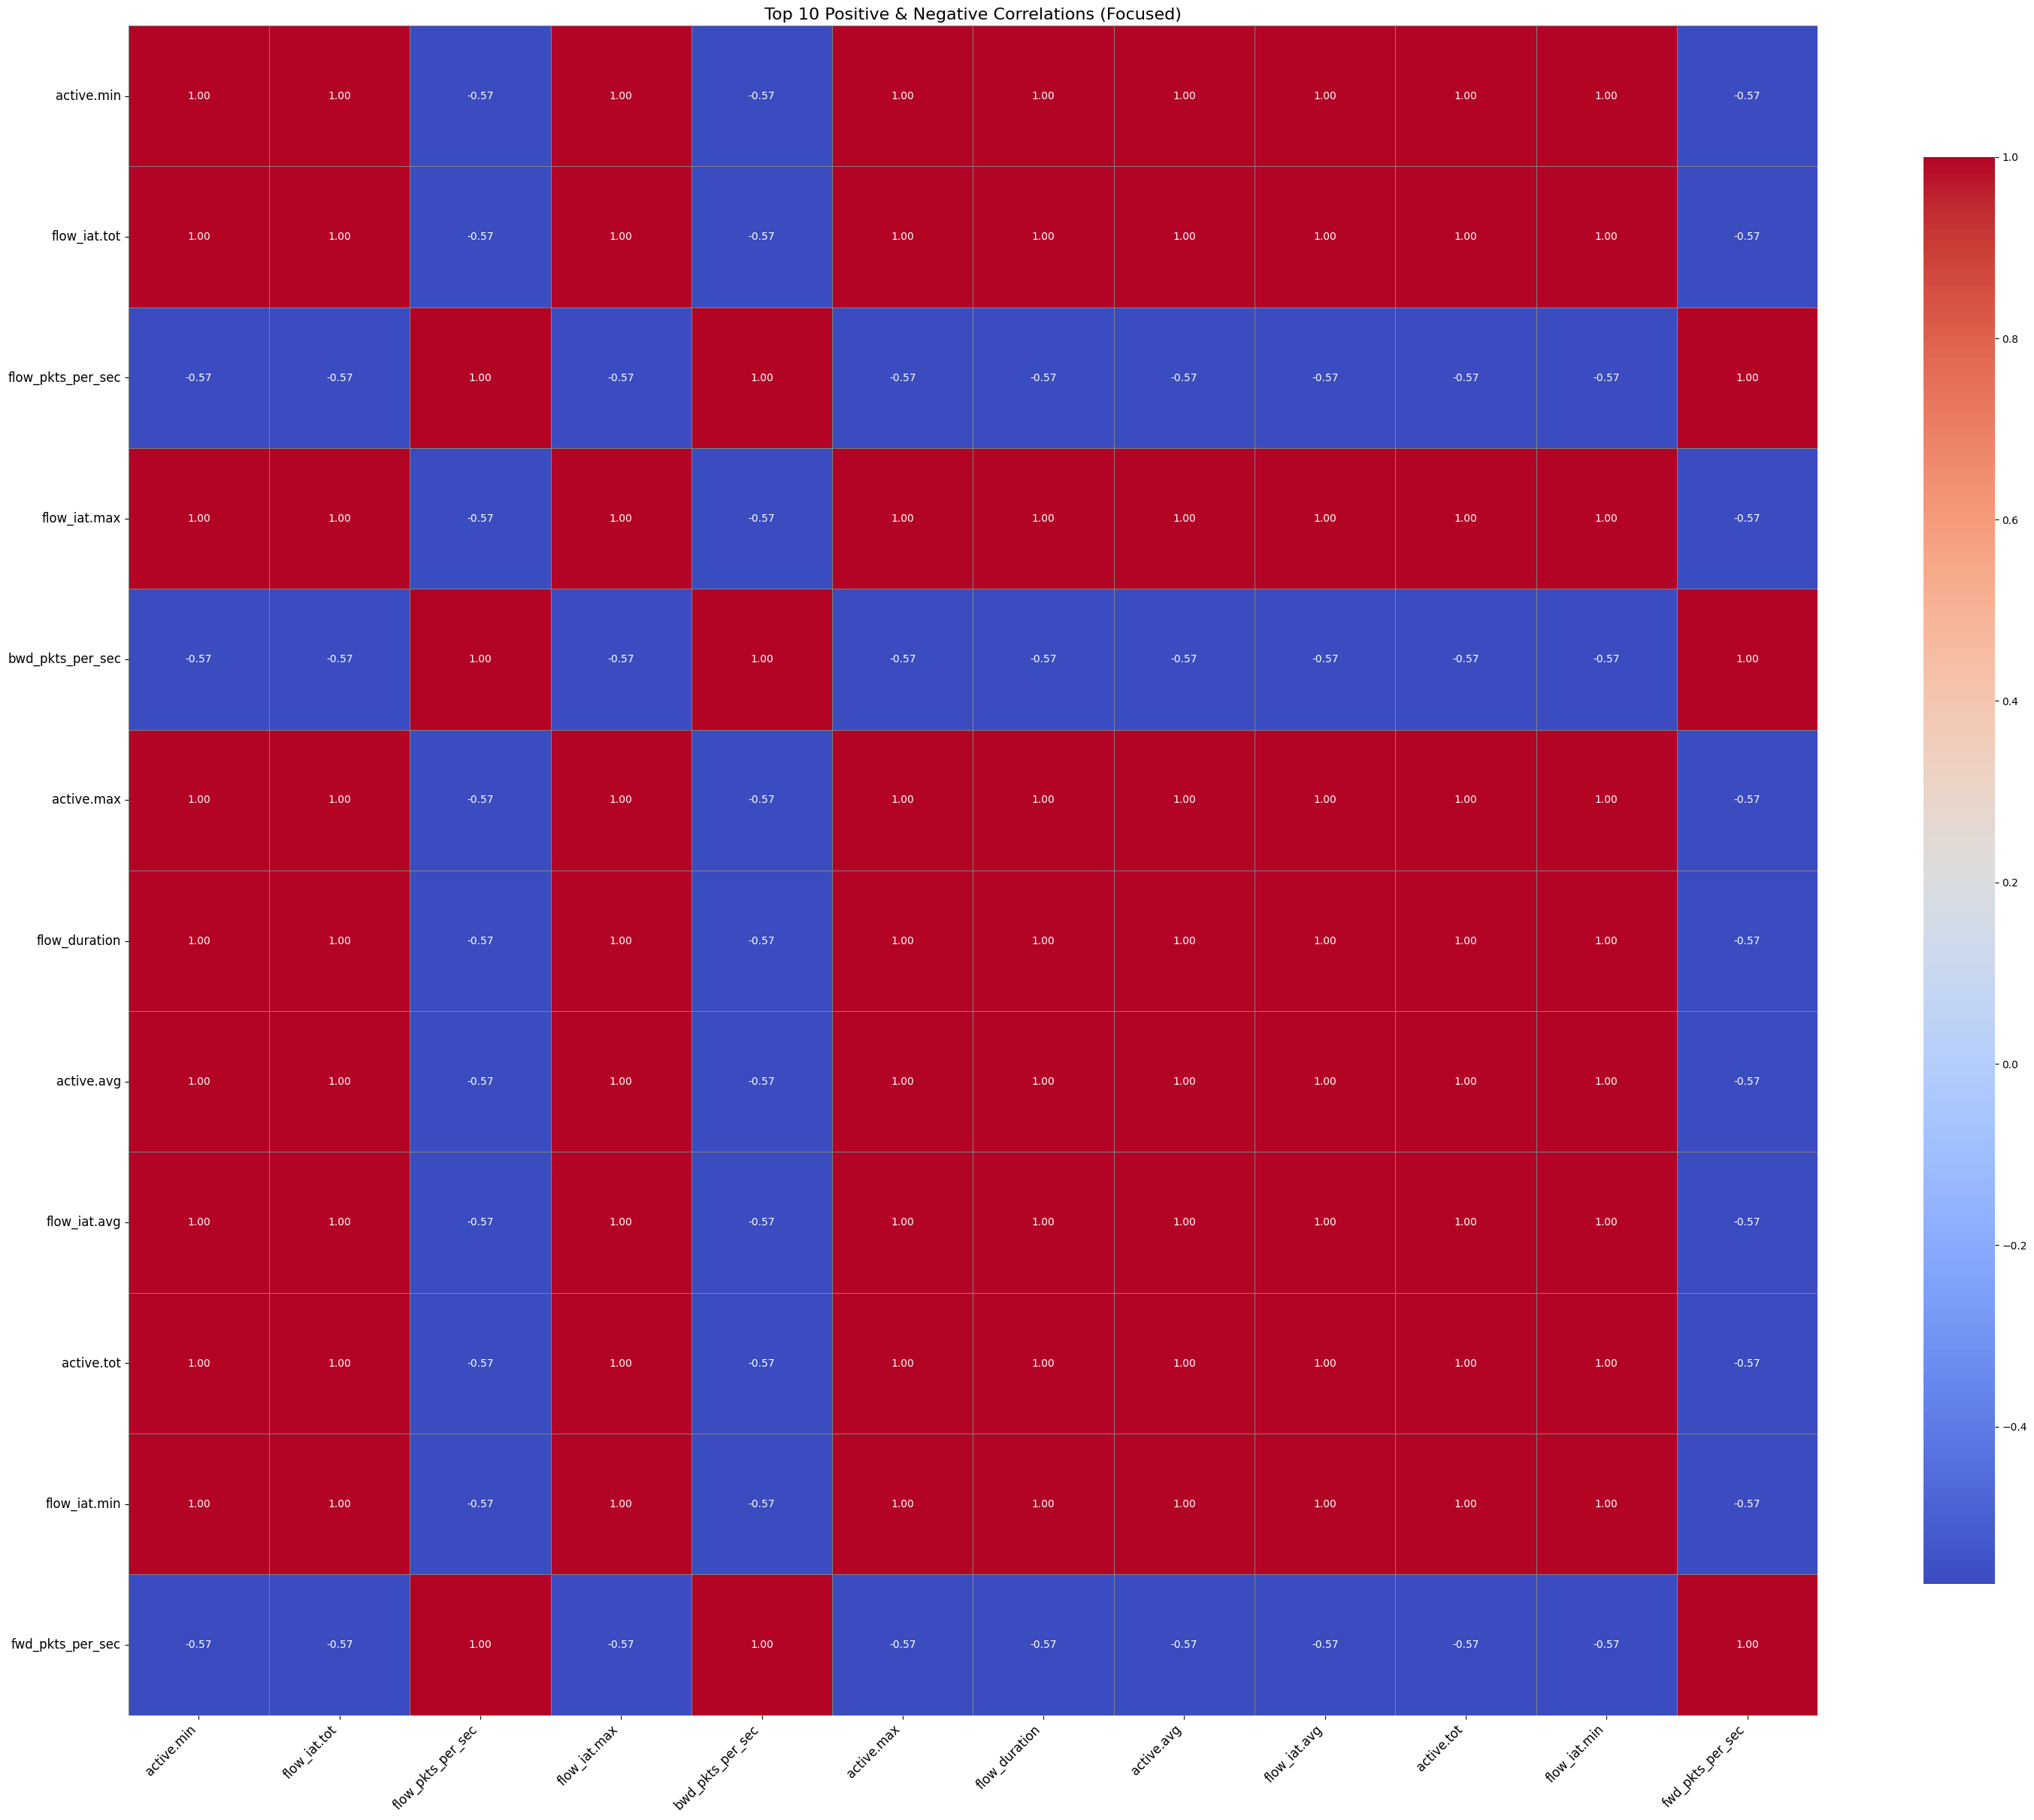

In [49]:

nmap_xmas=pd.read_csv('NMAP_XMAS_TREE_SCAN.csv')
plot_focused_top_correlations(nmap_xmas, top_n=10)

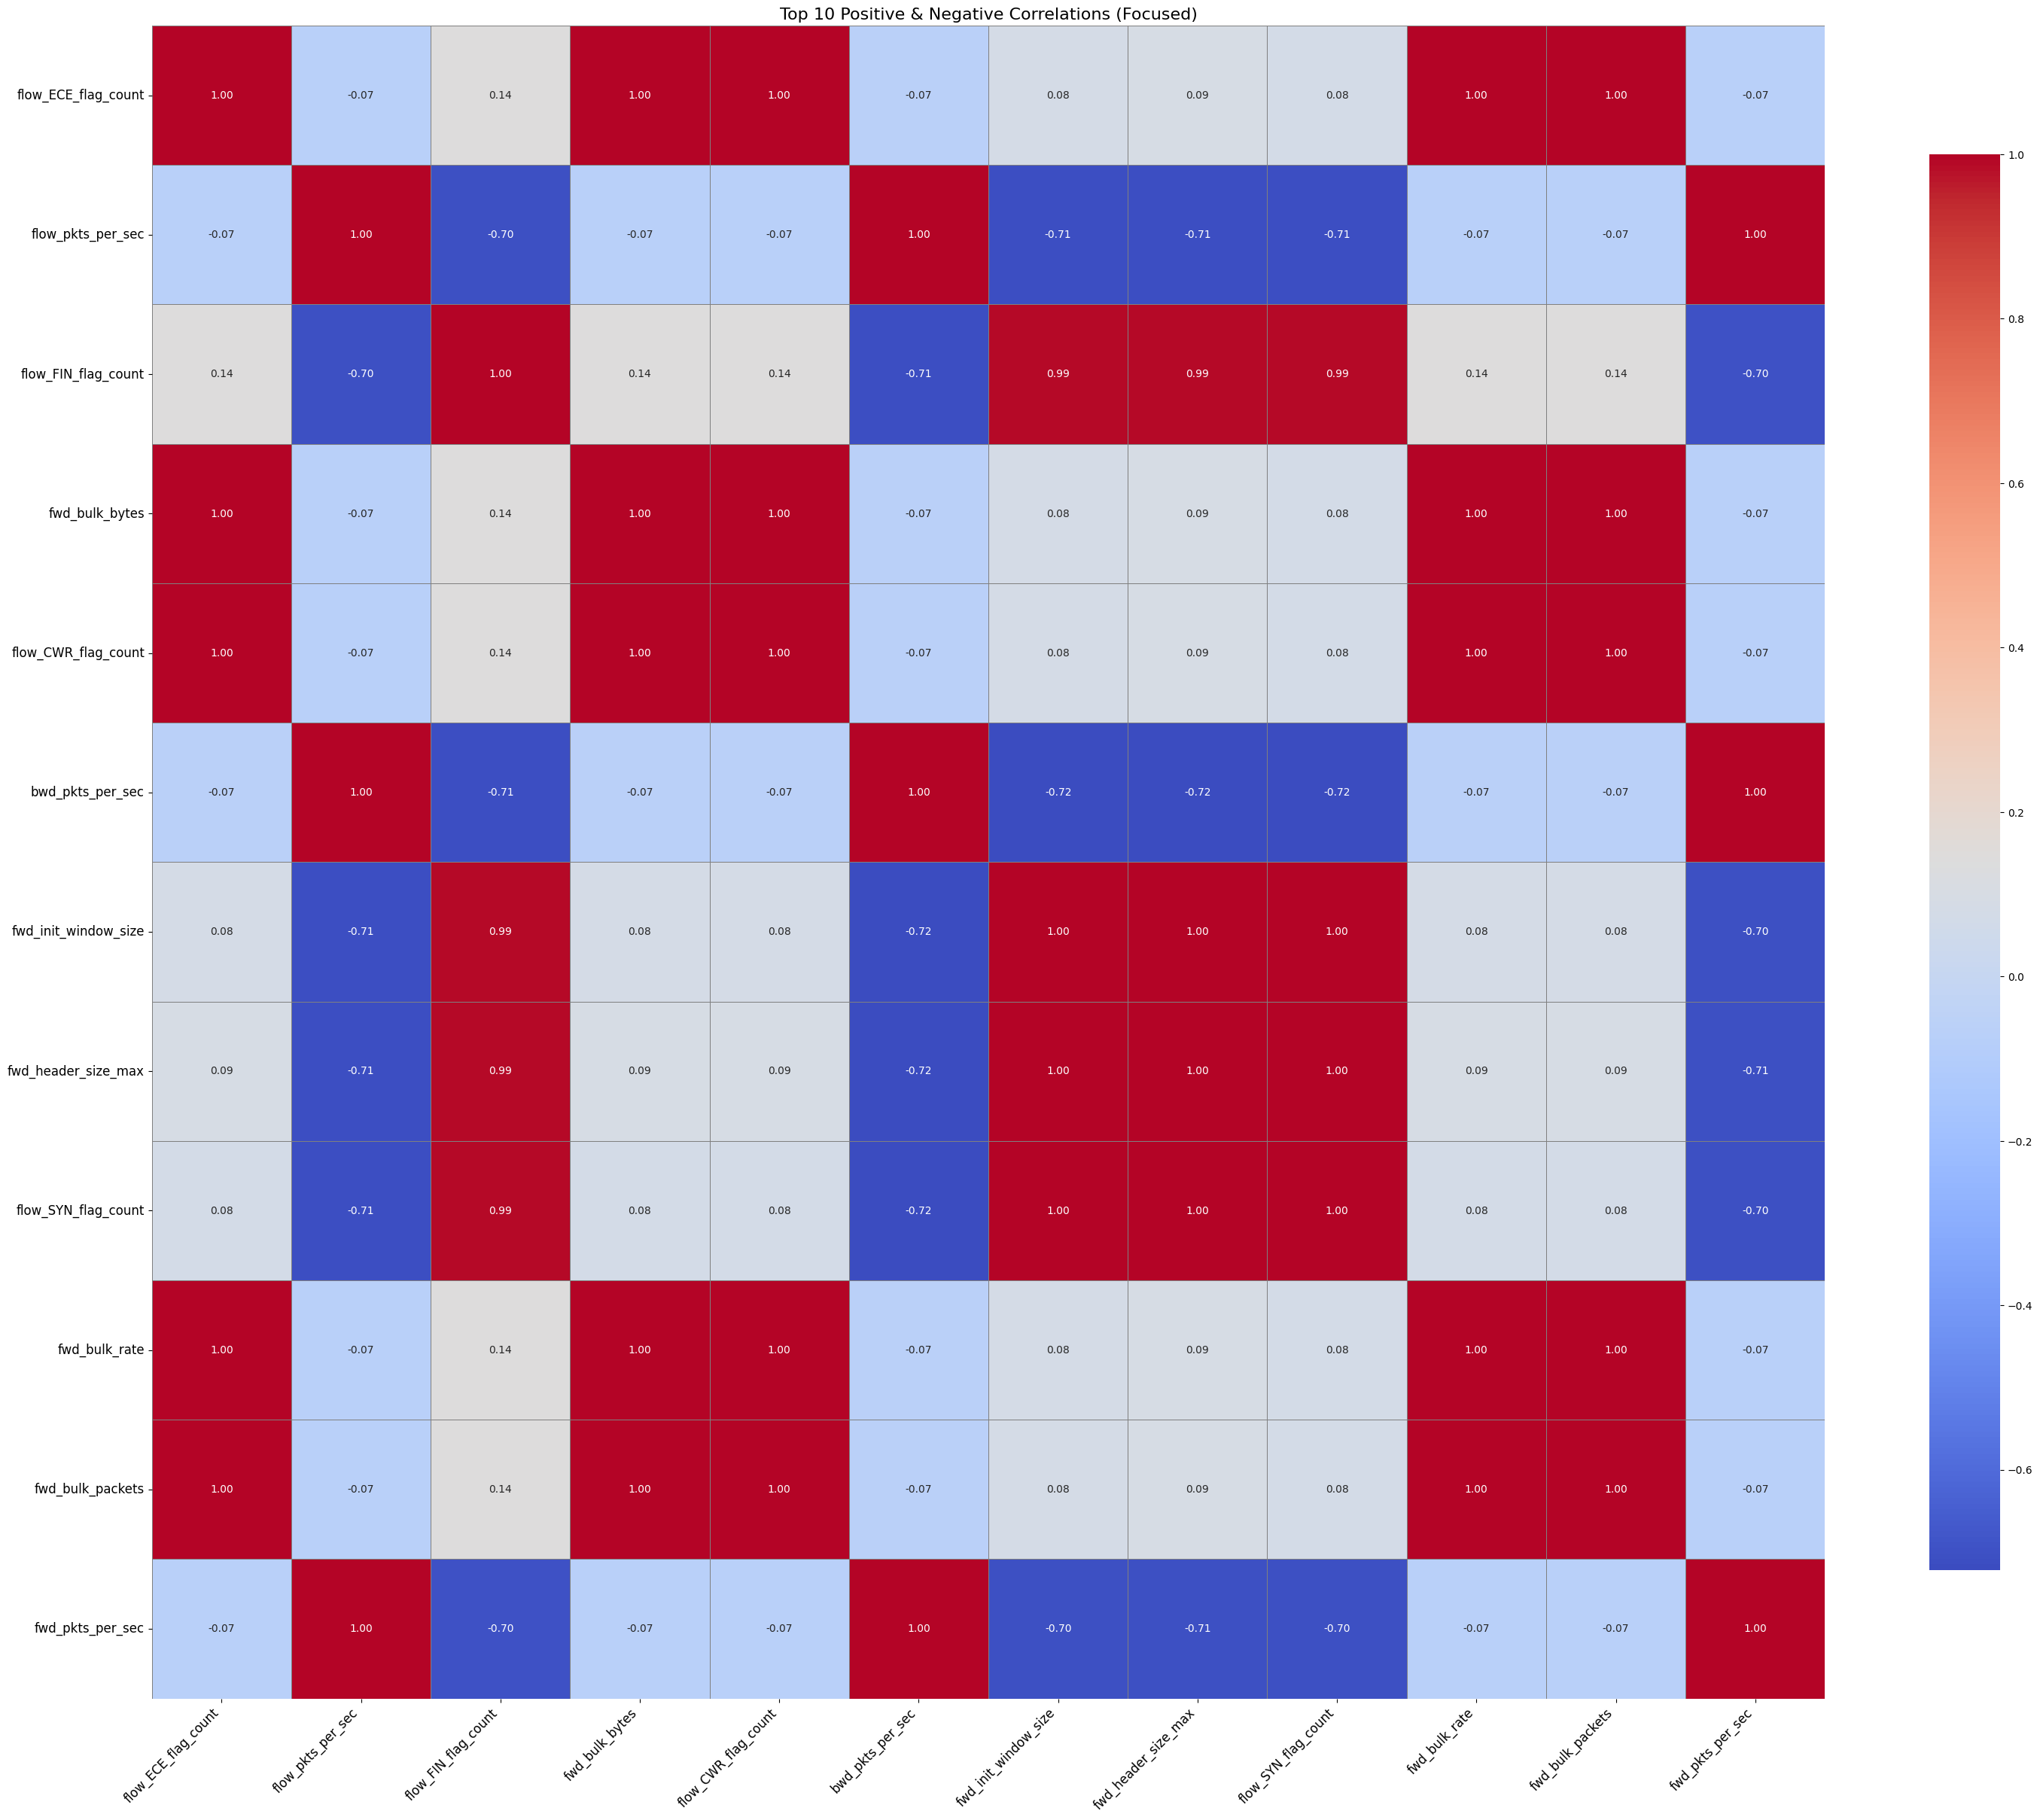

In [50]:

thing=pd.read_csv('Thing_Speak.csv')
plot_focused_top_correlations(thing, top_n=10)

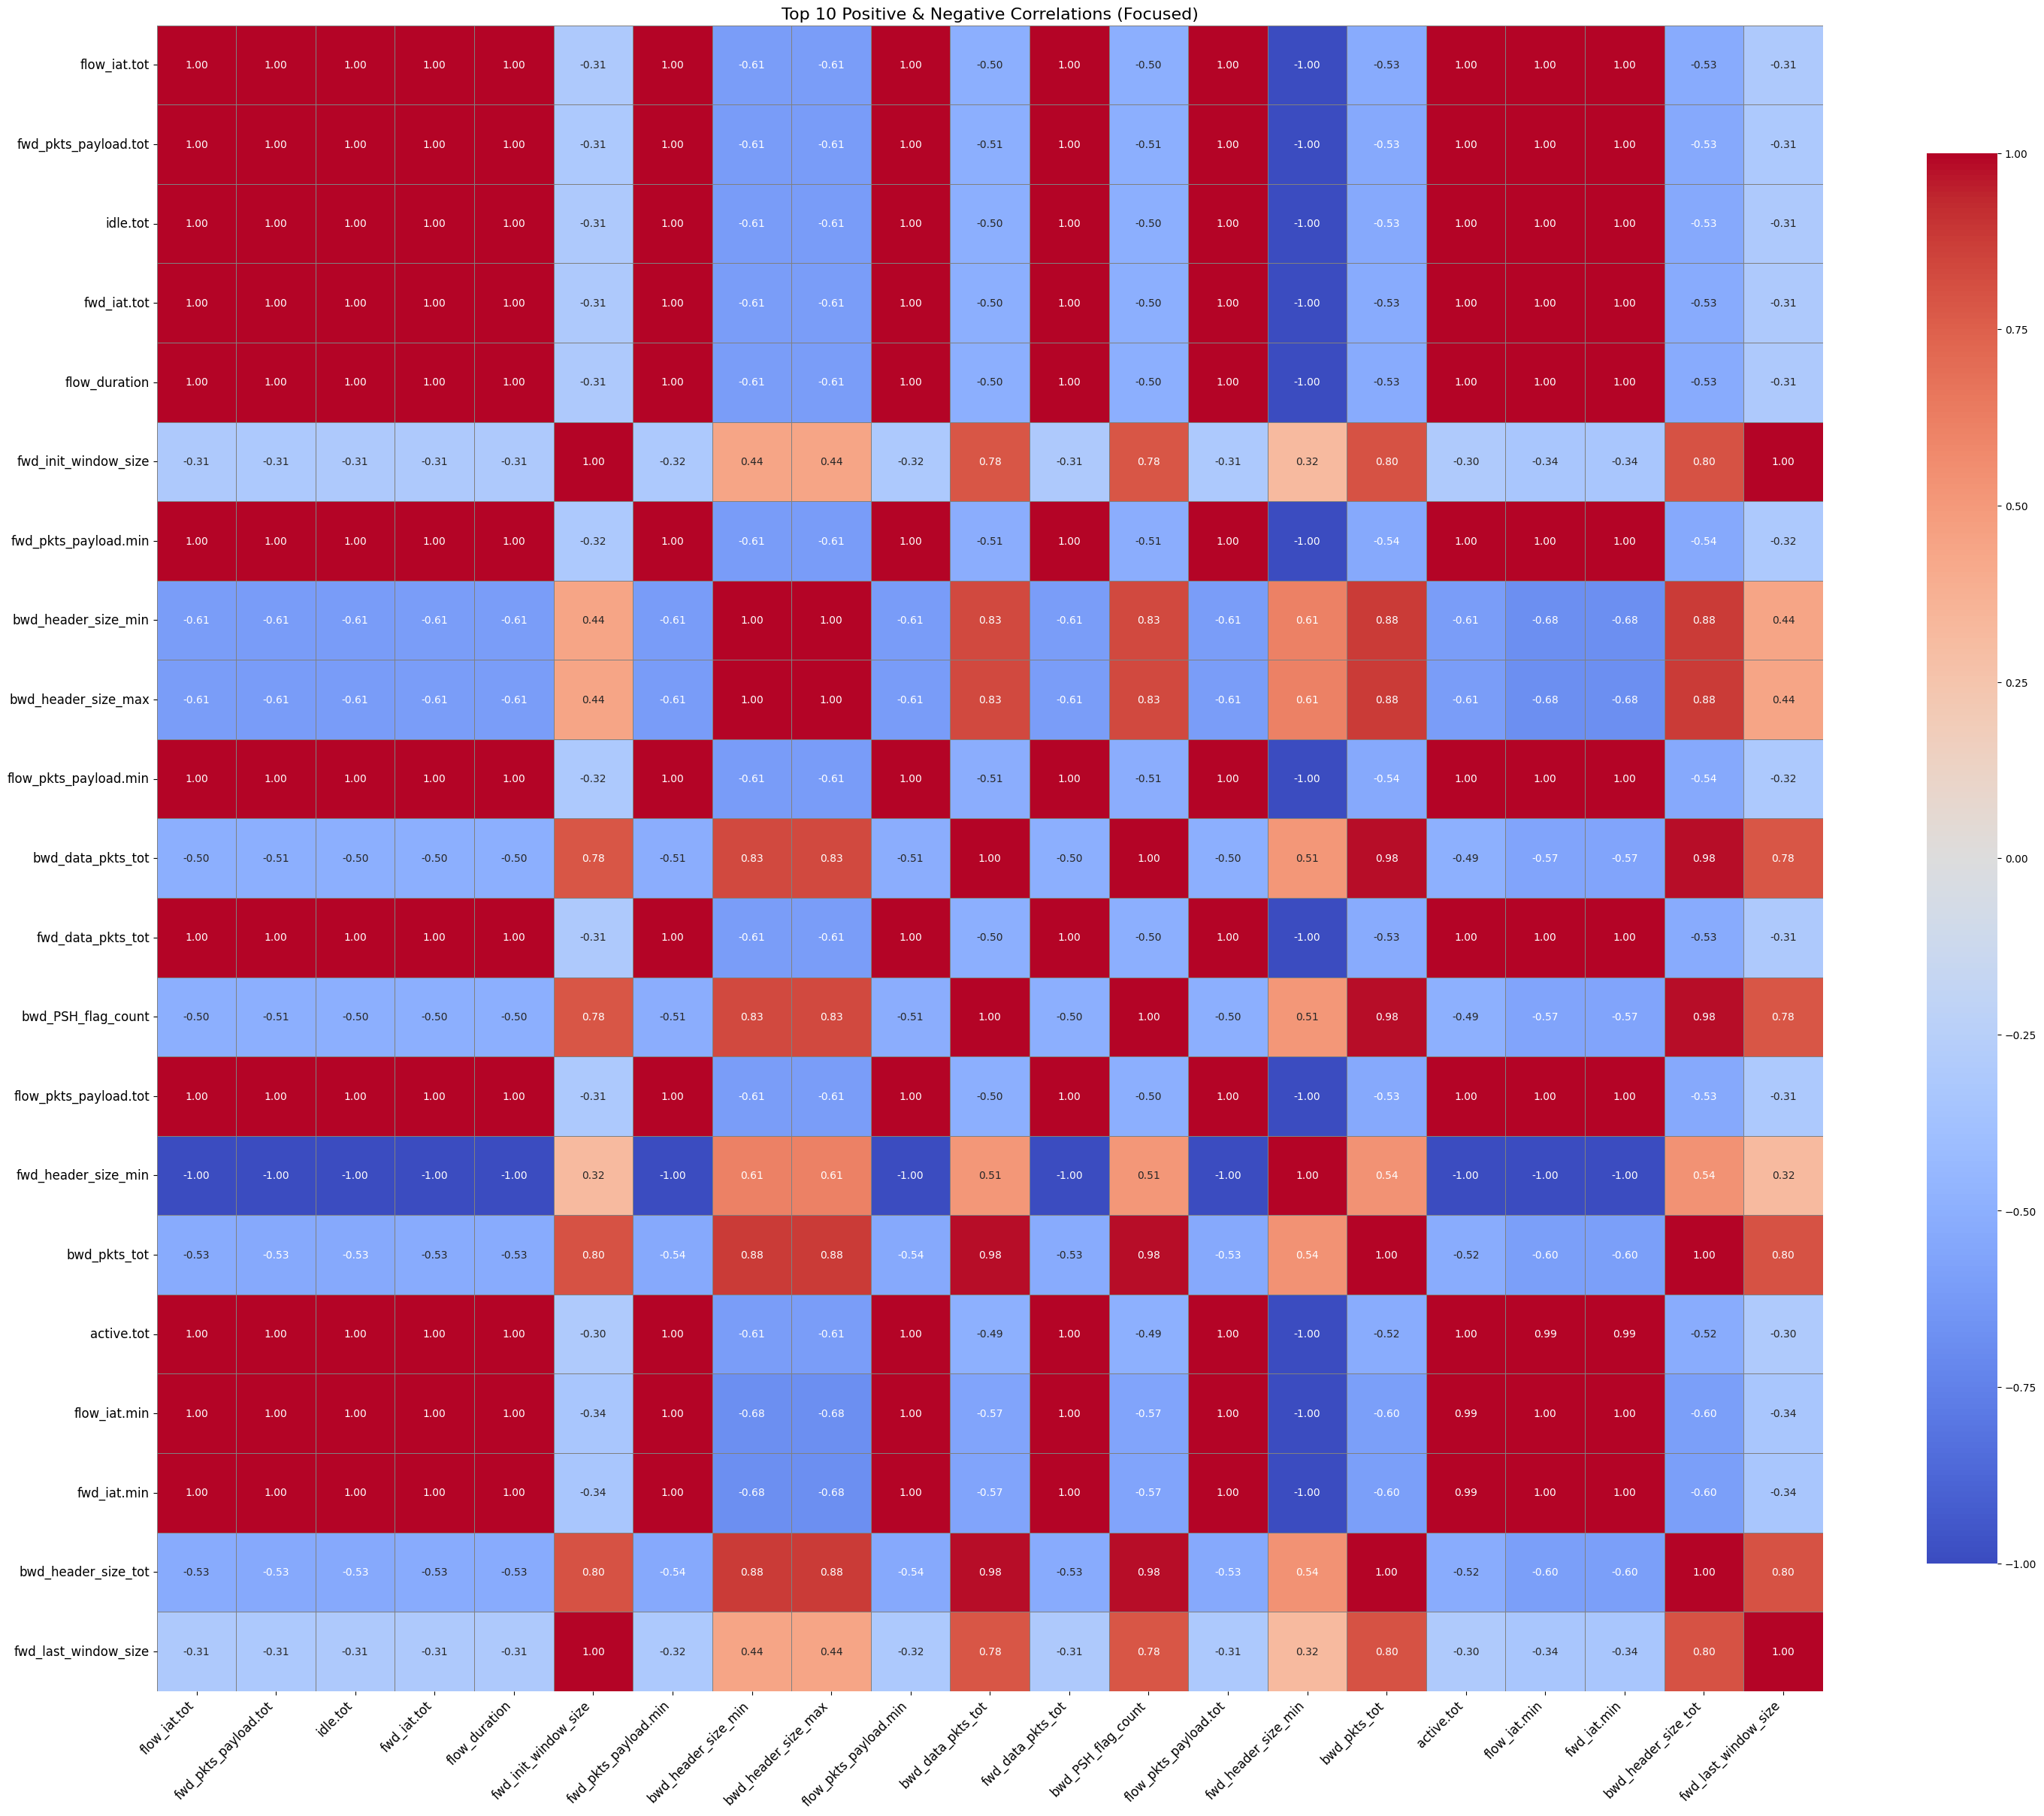

In [51]:

wipro=pd.read_csv('Wipro_bulb.csv')
plot_focused_top_correlations(wipro, top_n=10)